# Attack detection on the Weather device (TON_IoT)
**Models:** Decision Tree • Random Forest • XGBoost • LightGBM • CatBoost

## Notebook steps
1. **EDA:** understand the data with plots before any model
2. **Cleaning + 10-second windows:** clean the data and group it into 10-second windows, with context from previous windows
3. **Safe split:** hash-based blocks, shared by every device, no data leakage
4. **Training:** train 5 models and compare them
5. **Deep dive:** confusion matrix, ROC, feature importance, threshold (and recall target)
6. **Block cross-validation:** check that the result is stable and not luck
7. **Multi-class:** identify the attack type
8. **Ablation + random split demo:** check that the result is honest
9. **Calibration, anomaly score and export:** unified detection events for the aggregation step

## 3 rules against leakage and overfitting
- The `type` column is not a feature because it is the label itself (same for `date` and `time`)
- The split uses contiguous time blocks, not random rows (neighbouring rows are very similar)
- Thresholds and model choices are made on validation only, and the test set is used once at the end

In [1]:
!pip install -q catboost

In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             roc_curve, precision_recall_curve, roc_auc_score)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", rc={"axes.grid.axis": "y"})
plt.rcParams["figure.dpi"] = 100
SEED = 42
SENSORS = ["temperature", "pressure", "humidity"]
DATA_PATH = os.environ.get("DATA_PATH", "/content/IoT_Weather.csv")

if not os.path.exists(DATA_PATH):
    from google.colab import files
    DATA_PATH = "/content/" + list(files.upload().keys())[0]

# 1) EDA

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)

Shape: (650242, 7)


In [4]:
raw.head()

,date,time,temperature,pressure,humidity,label,type
0,31-Mar-19,12:36:52,31.788508,1.035,32.036579,0,normal
1,31-Mar-19,12:36:53,41.630997,1.035,30.886165,0,normal
2,31-Mar-19,12:36:54,42.256959,1.035,19.755908,0,normal
3,31-Mar-19,12:36:55,49.116581,1.035,78.949621,0,normal
4,31-Mar-19,12:36:56,24.017085,1.035,40.001059,0,normal


In [5]:
print(raw.dtypes, "\n")

date            object
time            object
temperature    float64
pressure       float64
humidity       float64
label            int64
type            object
dtype: object 



In [6]:
print("Missing values:\n", raw.isna().sum(), "\n")

Missing values:
 date           0
time           0
temperature    0
pressure       0
humidity       0
label          0
type           0
dtype: int64 



In [7]:
print("Exact duplicates:", raw.duplicated().sum())

Exact duplicates: 26045


In [8]:
raw["time"] = raw["time"].str.strip()

In [9]:
print("Duplicates after cleaning the time column:", raw.duplicated().sum())

Duplicates after cleaning the time column: 49219


In [10]:
raw[SENSORS].describe().round(2)

,temperature,pressure,humidity
count,650242.00,650242.00,650242.00
mean,36.07,2.01,51.64
std,8.18,7.95,27.04
min,20.51,-37.63,0.00
25%,29.12,0.04,28.66
50%,36.78,1.29,52.65
75%,43.06,4.13,74.65
max,50.00,26.69,99.89


In [11]:
raw["label"].value_counts()

,count
label,
0,559718
1,90524


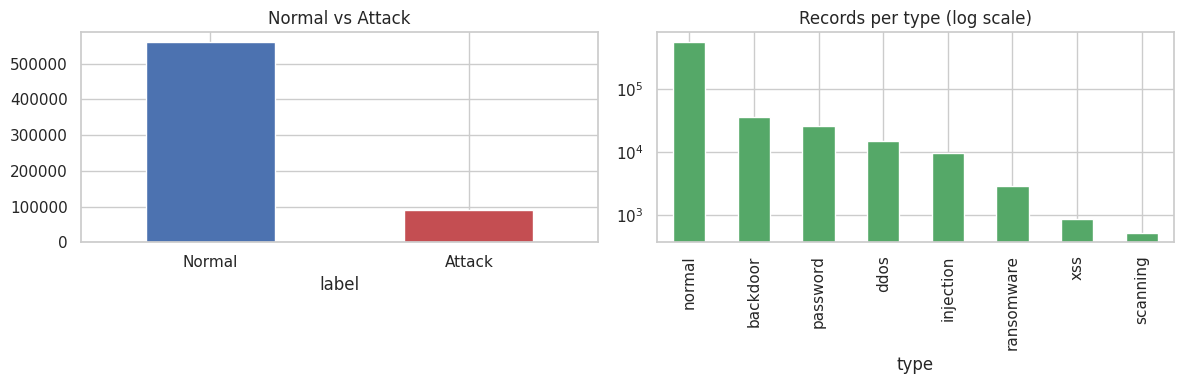

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
raw["label"].map({0: "Normal", 1: "Attack"}).value_counts().plot.bar(ax=ax[0], color=["#4c72b0", "#c44e52"], rot=0)
ax[0].set_title("Normal vs Attack")
raw["type"].value_counts().plot.bar(ax=ax[1], color="#55a868")
ax[1].set_yscale("log"); ax[1].set_title("Records per type (log scale)")
plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Class Distribution Analysis</h2>
<h3>Normal vs Attack (left chart)</h3>
<ul>
  <li>The dataset is <b>imbalanced</b>: Normal records (~560,000) are much more than Attack records (~90,000).</li>
  <li>Normal traffic is about <b>6x</b> larger than Attack traffic.</li>
  <li>A model could get high accuracy just by predicting "Normal" every time, so accuracy alone is not a good metric.</li>
</ul>
<h3>Records per type (right chart, log scale)</h3>
<ul>
  <li>The y-axis uses a <b>log scale</b> because the differences between classes are very large.</li>
  <li><b>normal</b> is the biggest class by far (~500,000+ records).</li>
  <li>The attack types are also imbalanced:
    <ul>
      <li><b>backdoor</b> (~35,000), <b>password</b> (~25,000), <b>ddos</b> (~15,000), <b>injection</b> (~10,000) are medium-sized.</li>
      <li><b>ransomware</b> (~3,000), <b>xss</b> (~800), <b>scanning</b> (~500) are very small classes.</li>
    </ul>
  </li>
  <li>The difference between the largest attack type and the smallest is about <b>70x</b>.</li>
</ul>
<h3>Conclusion</h3>
<ul>
  <li>The data has <b>two levels of imbalance</b>: Normal vs Attack, and between the attack types themselves.</li>
  <li>Rare classes like <b>xss</b>, <b>scanning</b>, and <b>ransomware</b> will be hard for the model to learn.</li>
</ul>
</div>

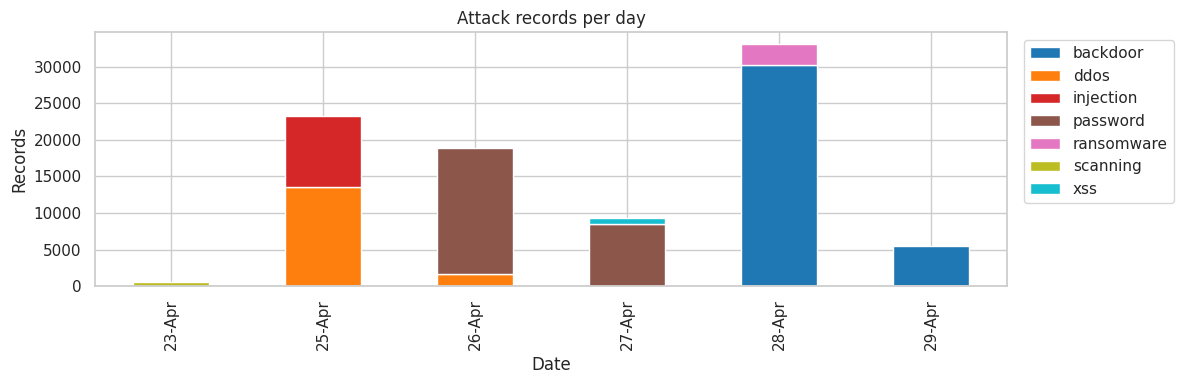

In [13]:
day = pd.to_datetime(raw["date"], format="%d-%b-%y")
att = raw[raw["label"] == 1]
pd.crosstab(day[att.index].dt.strftime("%d-%b"), att["type"]).plot.bar(stacked=True, figsize=(12, 4), colormap="tab10")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("Attack records per day"); plt.xlabel("Date"); plt.ylabel("Records"); plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Attack Records per Day Analysis</h2>

<h3>Daily volume</h3>
<ul>
  <li>The attacks happen over <b>6 days</b> (23-Apr to 29-Apr), and there is <b>no attack data on 24-Apr</b>.</li>
  <li>The highest day is <b>28-Apr</b> with about <b>33,000</b> attack records.</li>
  <li>The lowest day is <b>23-Apr</b> with only about <b>500</b> records.</li>
</ul>

<h3>Attack types by day</h3>
<ul>
  <li><b>23-Apr:</b> only <b>scanning</b> (very small).</li>
  <li><b>25-Apr:</b> <b>ddos</b> (~13,500) and <b>injection</b> (~9,800).</li>
  <li><b>26-Apr:</b> mostly <b>password</b> (~17,000) with a small amount of <b>ddos</b>.</li>
  <li><b>27-Apr:</b> mostly <b>password</b> (~8,500) with a small amount of <b>xss</b>.</li>
  <li><b>28-Apr:</b> mostly <b>backdoor</b> (~30,000) and some <b>ransomware</b> (~3,000).</li>
  <li><b>29-Apr:</b> only <b>backdoor</b> (~5,500).</li>
</ul>

<h3>Key observations</h3>
<ul>
  <li>Attacks are <b>not spread evenly</b>: each attack type is concentrated in specific days, like planned attack campaigns.</li>
  <li><b>Ransomware</b> appears only on 28-Apr, <b>scanning</b> only on 23-Apr, and <b>injection</b> only on 25-Apr.</li>
  <li><b>xss</b> is very small and appears only on 27-Apr.</li>
</ul>

<h3>Conclusion and impact on modeling</h3>
<ul>
  <li>A <b>random split</b> is fine for training, but a <b>time-based split</b> could leave some attack types completely out of the training set.</li>
  <li>The date should <b>not</b> be used as a feature, because the model may learn "which day" instead of the real attack behavior (data leakage).</li>
  <li>Rare types (<b>scanning</b>, <b>xss</b>, <b>ransomware</b>) exist in only one day each, so use <b>stratified split</b>, class weights, or SMOTE to help the model learn them.</li>
</ul>
</div>

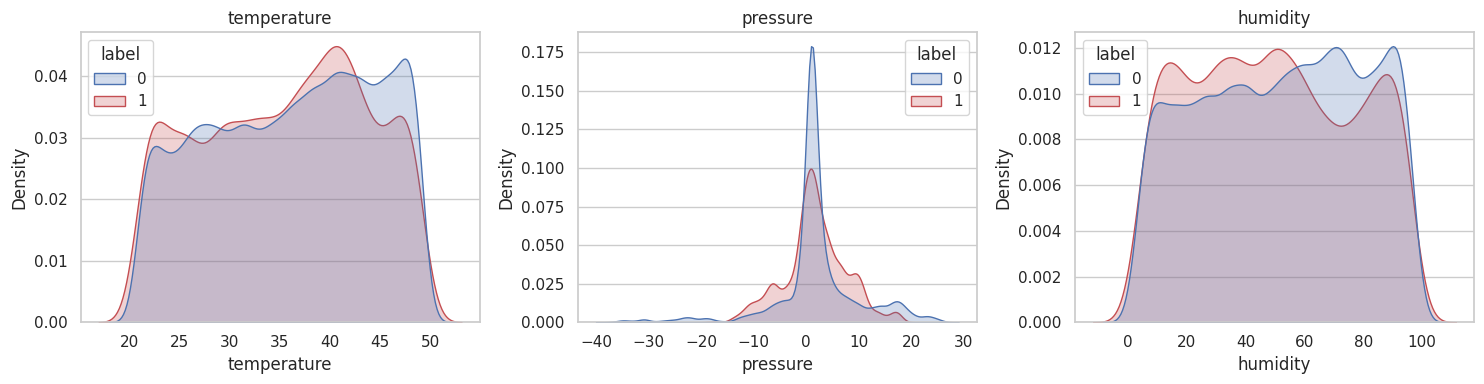

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, SENSORS):
    sns.kdeplot(data=raw.sample(100_000, random_state=SEED), x=c, hue="label", common_norm=False,
                fill=True, palette=["#4c72b0", "#c44e52"], ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Feature Distribution by Label (KDE Plots)</h2>

<h3>How to read the plots</h3>
<ul>
  <li>Each plot shows the <b>density</b> (how common each value is) of one sensor feature.</li>
  <li><b>Blue (label 0)</b> = Normal, <b>Red (label 1)</b> = Attack.</li>
  <li>If the two curves overlap a lot, the feature is <b>weak</b> at separating the classes. If they are different, the feature is <b>useful</b>.</li>
</ul>

<h3>Temperature</h3>
<ul>
  <li>The two curves are very <b>similar and overlapping</b>, range about 20 to 50.</li>
  <li>Small differences only: Attack is a bit higher around <b>40</b>, Normal is a bit higher around <b>47</b>.</li>
  <li>Weak separation when used alone.</li>
</ul>

<h3>Pressure</h3>
<ul>
  <li>Most values are concentrated <b>around 0</b>.</li>
  <li>Normal has a <b>very sharp and high peak</b> (~0.18), while Attack has a <b>lower and wider</b> peak (~0.10), so Attack values are more spread out.</li>
  <li>Normal has a few extreme values (about -40 to -20 and 20 to 25), which may be <b>outliers</b>.</li>
  <li>This is the <b>clearest difference</b> between the two classes.</li>
</ul>

<h3>Humidity</h3>
<ul>
  <li>Values are spread almost evenly from <b>0 to 100</b>.</li>
  <li>Attack is a bit higher in the <b>low range (10 to 50)</b>, and Normal is higher in the <b>high range (60 to 90)</b>.</li>
  <li>Medium separation.</li>
</ul>

<h3>Conclusion</h3>
<ul>
  <li>No single feature separates Attack from Normal clearly. <b>Pressure</b> is the most useful, then <b>humidity</b>, then <b>temperature</b>.</li>
  <li>The model needs to combine these features with the other columns to detect attacks.</li>
  <li>Check the <b>outliers in pressure</b> and decide whether to keep, cap, or remove them.</li>
</ul>
</div>

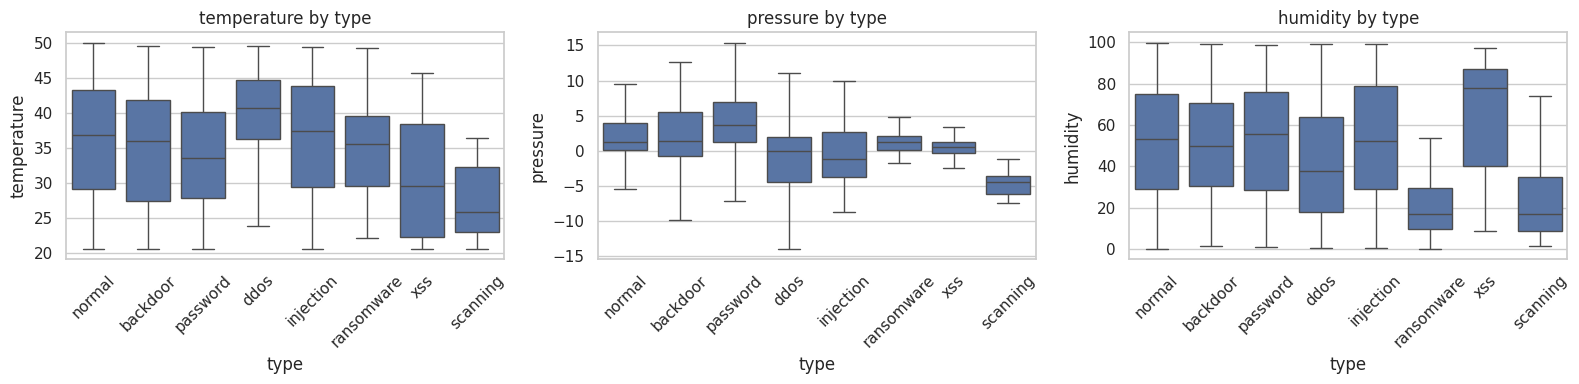

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
order = raw["type"].value_counts().index
for a, c in zip(ax, SENSORS):
    sns.boxplot(data=raw, x="type", y=c, order=order, showfliers=False, ax=a)
    a.tick_params(axis="x", rotation=45); a.set_title(f"{c} by type")
plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Feature Distribution by Attack Type (Box Plots)</h2>

<h3>How to read the plots</h3>
<ul>
  <li>The <b>line inside the box</b> is the median, and the <b>box</b> covers the middle 50% of the values.</li>
  <li>If a box is far from the <b>normal</b> box, the feature helps to separate that type from normal traffic.</li>
  <li>A <b>narrow box</b> means the values of that type are very stable.</li>
</ul>

<h3>Temperature</h3>
<ul>
  <li><b>ddos</b> has the highest temperature (median ~40), and <b>scanning</b> has the lowest (median ~26). <b>xss</b> is also low (~30).</li>
  <li>normal, backdoor, password, injection, and ransomware are <b>very close</b> to each other.</li>
</ul>

<h3>Pressure</h3>
<ul>
  <li><b>scanning</b> is clearly different: median ~-4.5, below all other types, with a narrow box.</li>
  <li><b>password</b> is a bit higher than the others (median ~4).</li>
  <li><b>ddos</b> and <b>injection</b> are around 0 or slightly below, but with a wide range of values.</li>
  <li><b>ransomware</b> and <b>xss</b> have very narrow boxes, so their values are stable.</li>
</ul>

<h3>Humidity</h3>
<ul>
  <li><b>ransomware</b> and <b>scanning</b> have very low humidity (median ~17).</li>
  <li><b>xss</b> has the highest humidity (median ~78).</li>
  <li><b>ddos</b> is lower than normal (median ~38).</li>
  <li>normal, backdoor, password, and injection are <b>similar</b>.</li>
</ul>

<h3>Conclusion</h3>
<ul>
  <li><b>scanning</b>, <b>ransomware</b>, <b>xss</b>, and <b>ddos</b> have a different pattern from normal, so they should be easier for the model to detect.</li>
  <li><b>backdoor</b>, <b>password</b>, and <b>injection</b> look very similar to normal, so the model may confuse them with normal traffic.</li>
  <li>Sensor features alone are not enough, so we need to use the <b>other columns</b> too (network features) to separate these types.</li>
</ul>
</div>

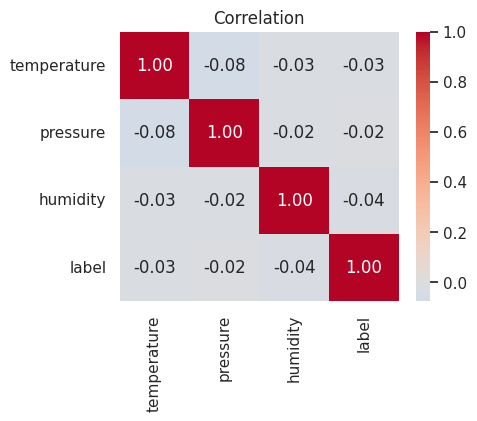

In [16]:
plt.figure(figsize=(4.5, 3.5))
sns.heatmap(raw[SENSORS + ["label"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation"); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Correlation Analysis</h2>

<h3>How to read the heatmap</h3>
<ul>
  <li>Values range from <b>-1 to +1</b>: +1 is a perfect positive relation, -1 is a perfect negative relation, and <b>0 means no linear relation</b>.</li>
  <li>The diagonal is always 1.00 because each column is compared with itself.</li>
</ul>

<h3>Features vs each other</h3>
<ul>
  <li>The correlations between <b>temperature</b>, <b>pressure</b>, and <b>humidity</b> are very close to 0 (from -0.08 to -0.02).</li>
  <li>The features are <b>independent</b>, so there is no multicollinearity problem.</li>
</ul>

<h3>Features vs label</h3>
<ul>
  <li><b>temperature</b> (-0.03), <b>pressure</b> (-0.02), and <b>humidity</b> (-0.04) are all almost 0.</li>
  <li>There is <b>no linear relationship</b> between any sensor feature and the label.</li>
</ul>

<h3>Conclusion</h3>
<ul>
  <li>The sensor features are <b>weak predictors alone</b>, which matches the KDE and box plots (differences are small).</li>
  <li>Correlation measures only <b>linear</b> relations, so these features may still help with <b>non-linear</b> patterns or when combined with other columns.</li>
  <li>We should <b>not drop</b> them based on correlation only, and we should use tree-based models and the other (network) features.</li>
</ul>
</div>

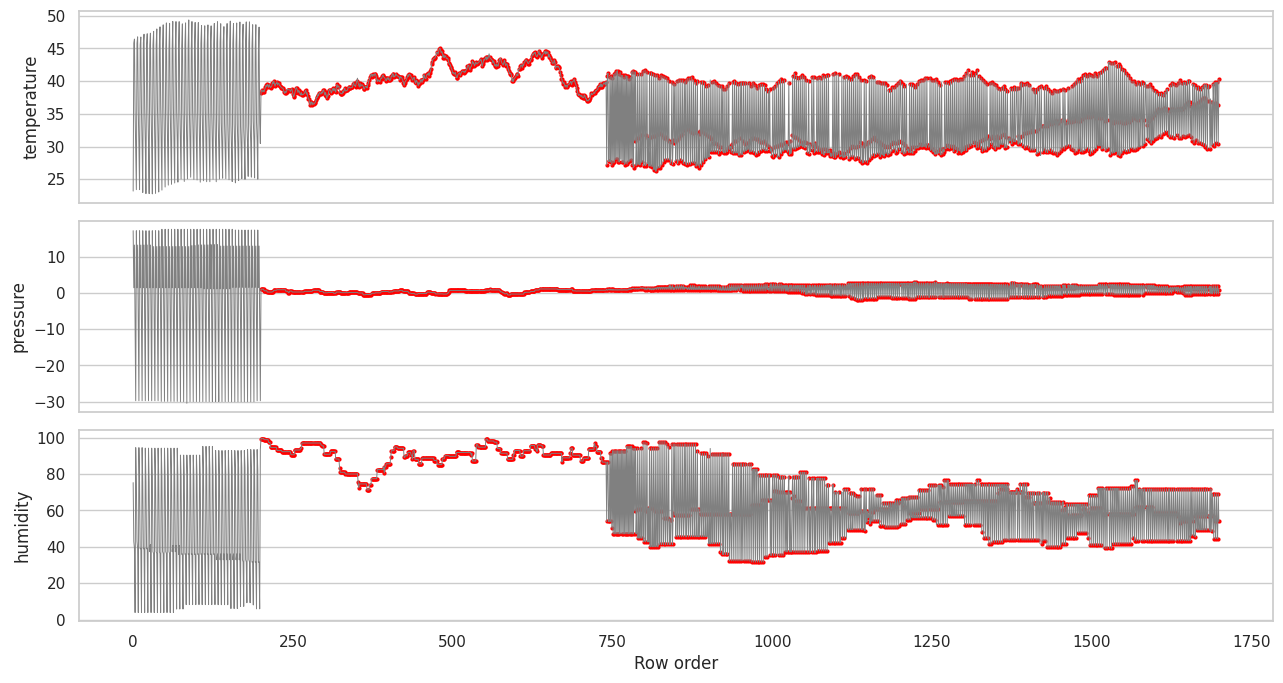

In [17]:
first = raw.index[raw["label"] == 1][0]
seg = raw.iloc[first - 200 : first + 1500].reset_index(drop=True)
fig, ax = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
for a, c in zip(ax, SENSORS):
    a.plot(seg[c], lw=0.7, color="gray")
    a.scatter(seg.index[seg.label == 1], seg.loc[seg.label == 1, c], s=4, color="red")
    a.set_ylabel(c)
ax[-1].set_xlabel("Row order"); plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Sensor Values by Row Order (Time Series)</h2>

<h3>How to read the plot</h3>
<ul>
  <li>Each panel shows one sensor (<b>temperature</b>, <b>pressure</b>, <b>humidity</b>) across the row order of the data.</li>
  <li>The <b>gray line</b> is the sensor value, and the <b>red dots</b> mark the <b>Attack</b> rows (label 1).</li>
</ul>

<h3>Three clear phases</h3>
<ul>
  <li><b>Rows 0 to ~200:</b> values jump very fast and cover a <b>wide range</b> (temperature 23-49, pressure -30 to +17, humidity 5-95). This looks like normal data with almost no attacks.</li>
  <li><b>Rows ~200 to ~740:</b> the line becomes <b>smooth and stable</b> and the red dots appear. Temperature is around 38-45, pressure is close to 0, and humidity is high (85-100). Attack values change <b>slowly</b> here.</li>
  <li><b>Rows ~740 to ~1700:</b> the line oscillates again, but the red dots follow the <b>upper and lower edges</b> of the range. Normal and Attack rows are <b>alternating</b>, and attacks sit at the extremes.</li>
</ul>

<h3>Key observations</h3>
<ul>
  <li>The behavior of the data <b>changes with row order</b>, so the data is <b>not randomly mixed</b>.</li>
  <li>This matches the attack-per-day plot, where each attack type appears in specific periods.</li>
  <li>Pressure in the attack phase is very <b>stable near 0</b>, while normal pressure has a much wider range.</li>
</ul>

<h3>Conclusion and impact on modeling</h3>
<ul>
  <li>Attack rows have a <b>different pattern</b> from normal rows, but the pattern depends on <b>order and time</b>.</li>
  <li>Do <b>not</b> use row index or date as a feature, because it can cause <b>data leakage</b>.</li>
  <li>Use a <b>stratified or shuffled split</b> carefully, and consider adding <b>rolling or lag features</b> (e.g. change from the previous row) to capture the sequence pattern.</li>
</ul>
</div>

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>EDA Summary: What We Learned</h2>

<ul>
  <li><b>Imbalanced data:</b> Normal records are about <b>6x</b> more than Attack records, and some attack types (<b>xss</b>, <b>scanning</b>, <b>ransomware</b>) are very rare.</li>
  <li><b>Attacks depend on the day:</b> each attack type appears in only one or two specific days, so the data is not evenly spread over time.</li>
  <li><b>Weak sensor features:</b> correlation with the label is almost 0 (-0.02 to -0.04) and the KDE curves overlap a lot, so the sensors alone do not separate Attack from Normal.</li>
  <li><b>Different attack signatures:</b> <b>scanning</b>, <b>ransomware</b>, <b>xss</b> and <b>ddos</b> look different from normal, while <b>backdoor</b>, <b>password</b> and <b>injection</b> look very similar to normal.</li>
  <li><b>Independent features:</b> temperature, pressure and humidity are almost uncorrelated with each other, so there is no multicollinearity.</li>
  <li><b>Outliers in pressure:</b> some extreme values (about -40 to -20) appear in the first part of the data.</li>
  <li><b>Data has phases and order:</b> sensor behavior changes with the row order, and in the last phase the attacks sit at the edges of the value range.</li>
</ul>
</div>

# 2) Cleaning + 10-Second Windows


In [18]:
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Rows: {len(raw)} -> {len(df)} after removing duplicates")
#Remove exact duplicate rows and print the number of rows before and after

Rows: 650242 -> 601023 after removing duplicates


In [19]:
ts = pd.to_datetime(df["date"] + " " + df["time"], format="%d-%b-%y %H:%M:%S")
#Combine date and time into one timestamp ts

In [20]:
df["chunk"] = (ts.diff().dt.total_seconds() < 0).cumsum()
df["win"] = ((ts - pd.Timestamp("2019-01-01")).dt.total_seconds() // 10).astype(int)
#The file is made of several time parts stuck together. When the time goes backward, a new part chunk starts.
#Chunks keep us from mixing rows that are not really consecutive.
#Create 10-second windows
#Convert the time to seconds and divide by 10, so all rows in the same 10 seconds get the same win number

In [21]:
g = df.groupby(["chunk", "win"], sort=False)
W = g[SENSORS].agg(["mean", "std", "min", "max"])
W.columns = [f"{a}_{b}" for a, b in W.columns]
W["n_records"] = g.size()
#For each sensor (temperature, pressure, humidity) we calculate mean, std, min, max in each window.
#n_records is the number of rows in the window. It can help detect attacks like ddos that increase traffic.


In [22]:
# Count how many rows of each type (normal, ddos, ...) are inside each window
counts = pd.crosstab([df["chunk"], df["win"]], df["type"]).reindex(W.index)
# The window label = the most common type inside the window (majority vote)
W["type"] = counts.idxmax(axis=1).values
# Binary label: 1 if the window is an attack, 0 if it is normal
W["is_attack"] = (W["type"] != "normal").astype(int)
# Turn chunk and win from index back into normal columns, and fill missing values with 0
W = W.reset_index().fillna(0)

In [23]:
# Number of records in the previous window (same chunk only)
W["prev_n_records"] = W.groupby("chunk")["n_records"].shift(1).fillna(0)
# Time gap (in windows) between this window and the previous one
W["gap_prev"] = W.groupby("chunk")["win"].diff().fillna(0)

In [24]:
# Loop over the main columns we want to add history for
for c in ["pressure_mean", "pressure_std", "temperature_mean", "humidity_mean", "n_records"]:

    # Lag features: the value of this column 1, 2, and 3 windows ago
    for k in (1, 2, 3):
        W[f"{c}_lag{k}"] = W.groupby("chunk")[c].shift(k)

    # Rolling mean: average of the previous 3 windows (shift(1) excludes the current window)
    W[f"{c}_roll3"] = W.groupby("chunk")[c].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

    # Change feature: current value minus the recent average (shows sudden changes)
    W[f"{c}_chg"] = W[c] - W[f"{c}_roll3"]

# Fill the missing values (first windows of each chunk have no history) with 0
W = W.fillna(0)

# Use all columns as features except the identifiers (chunk, win) and the labels (type, is_attack)
FEATURES = [c for c in W.columns if c not in ("chunk", "win", "type", "is_attack")]

# Print: number of windows, percentage of attack windows, and number of features
print(f"Windows: {len(W)} | Attack windows: {W.is_attack.mean():.1%} | Features: {len(FEATURES)}")

Windows: 54906 | Attack windows: 29.8% | Features: 40


In [25]:
W.head()

,chunk,win,temperature_mean,temperature_std,temperature_min,temperature_max,pressure_mean,pressure_std,pressure_min,pressure_max,...,humidity_mean_lag1,humidity_mean_lag2,humidity_mean_lag3,humidity_mean_roll3,humidity_mean_chg,n_records_lag1,n_records_lag2,n_records_lag3,n_records_roll3,n_records_chg
0,0,773501,35.483476,8.342798,24.017085,49.116581,1.035000,0.000000,1.035000,1.03500,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,0,773502,34.817071,9.943390,21.444211,49.922575,0.999794,0.110277,0.599772,1.03500,...,30.171695,0.000000,0.000000,30.171695,8.214212,11.0,0.0,0.0,11.0,20.0
2,0,773503,35.137097,9.587550,20.968147,49.428453,1.008247,0.092536,0.599772,1.03500,...,38.385907,30.171695,0.000000,34.278801,12.107538,31.0,11.0,0.0,21.0,30.0
3,0,773504,35.455572,9.866830,20.855048,49.901756,1.017999,0.131135,0.566931,1.43363,...,46.386339,38.385907,30.171695,38.314647,11.390981,51.0,31.0,11.0,31.0,40.0
4,0,773505,35.878997,9.944859,20.795280,49.895635,1.013804,0.167429,0.558438,1.43363,...,49.705628,46.386339,38.385907,44.825958,4.592944,71.0,51.0,31.0,51.0,40.0


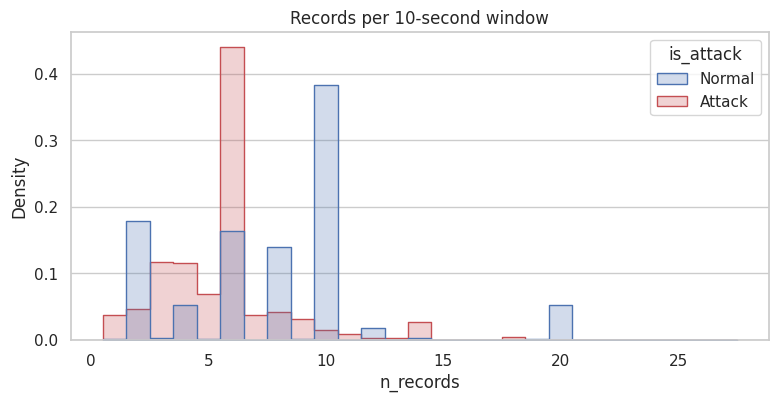

In [26]:
plt.figure(figsize=(9, 4))
sns.histplot(data=W[W.n_records <= 30], x="n_records", hue=W["is_attack"].map({0: "Normal", 1: "Attack"}),
             stat="density", common_norm=False, discrete=True, palette=["#4c72b0", "#c44e52"], element="step")
plt.title("Records per 10-second window"); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Result: Records per 10-Second Window</h2>
<ul>
  <li><b>Normal windows</b> are mostly at <b>10 records</b> (one row per second), with smaller groups at 2, 6, 8 and 20.</li>
  <li><b>Attack windows</b> are mostly at <b>6 records</b>, and most of them are between 3 and 8, so rows are often <b>missing</b> during attacks.</li>
  <li>A few attack windows have <b>13-14 records</b>, which is more than normal.</li>
  <li>The two classes <b>overlap</b> between 2 and 8, so <code>n_records</code> is useful but <b>not enough alone</b>.</li>
  <li>This supports using <b>n_records</b> and its <b>lag / rolling</b> versions as features.</li>
</ul>
</div>

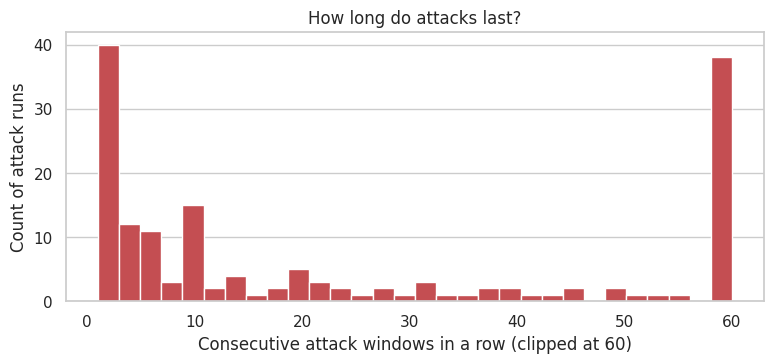

Median run = 10 windows | longest = 3004 windows


In [27]:
run_id = (W["is_attack"] != W["is_attack"].shift()).cumsum()
run_len = W[W.is_attack == 1].groupby(run_id).size()
plt.figure(figsize=(9, 3.5))
plt.hist(run_len.clip(upper=60), bins=30, color="#c44e52")
plt.xlabel("Consecutive attack windows in a row (clipped at 60)"); plt.ylabel("Count of attack runs")
plt.title("How long do attacks last?"); plt.show()
print(f"Median run = {run_len.median():.0f} windows | longest = {run_len.max()} windows")

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>How Long Do Attacks Last?</h2>

<h3>How to read the plot</h3>
<ul>
  <li>X-axis: the number of <b>consecutive attack windows</b> in a row (each window = 10 seconds). Values above 60 are <b>clipped</b> to 60.</li>
  <li>Y-axis: the <b>count of attack runs</b> (how many separate attack periods have this length).</li>
</ul>

<h3>What we see</h3>
<ul>
  <li><b>Very short attacks:</b> the highest bar is at 1-2 windows (about <b>40 runs</b>).</li>
  <li><b>Medium attacks:</b> few runs between 3 and 10 windows, with a small peak at <b>10</b> (about 15 runs).</li>
  <li><b>Long tail:</b> runs between 10 and 55 windows are rare (1 to 5 runs each).</li>
  <li><b>Very long attacks:</b> the second highest bar is at <b>60+</b> (about <b>38 runs</b>), which means 10 minutes or more.</li>
  <li>The distribution has a <b>U shape</b>: many very short and very long attacks, few in the middle.</li>
</ul>

<h3>Conclusion</h3>
<ul>
  <li>Attacks usually <b>continue for many windows</b>, which supports using <b>lag and rolling features</b> from previous windows.</li>
  <li>Very short attacks (1-2 windows) have little history, so they will be <b>harder to detect</b>.</li>
  <li>Neighboring windows inside one attack are very similar, so the train/test split should be by <b>chunks or time order</b>, not random, to avoid leakage.</li>
</ul>
</div>

In [28]:
# ---------- Hash-based block split (same rule on every device) ----------
import hashlib

BLOCK = 100                              # windows per block
SALT = "iot-anomaly"                     # shared salt, identical on every device
TRAIN_PCT, VAL_PCT = 70, 15              # hash buckets: [0,70) train, [70,85) val, [85,100) test

n = len(W)                               # total number of windows
all_idx = np.arange(n)                   # index of every window
types = W["type"].values                 # attack type of every window
n_types = W["type"].nunique()            # number of types

def assign_split(win, bw=BLOCK, salt=SALT):
    block = np.asarray(win) // bw        # absolute block number counted from the epoch, same on every device
    bucket = {b: int(hashlib.md5(f"{salt}:{b}".encode()).hexdigest(), 16) % 100 for b in np.unique(block)}
    r = np.array([bucket[b] for b in block])
    return np.where(r < TRAIN_PCT, "train", np.where(r < TRAIN_PCT + VAL_PCT, "val", "test"))

block_id = W["win"].values // BLOCK
split_name = assign_split(W["win"].values)
train, val, test = (np.where(split_name == s)[0] for s in ("train", "val", "test"))

# Remove the first 3 and last 3 windows of every block (safety gap),
# because lag / rolling features look at the previous 3 windows
pos = W["win"].values % BLOCK
edge = (pos < 3) | (pos >= BLOCK - 3)
train, val, test = [i[~edge[i]] for i in (train, val, test)]

# Safety check: no block is shared between two sets
assert not set(block_id[train]) & set(block_id[val])
assert not set(block_id[train]) & set(block_id[test])
assert not set(block_id[val])   & set(block_id[test])

# Features (X) and labels (y)
X, y = W[FEATURES], W["is_attack"].values
y_tr, y_va, y_te = y[train], y[val], y[test]

# Summary 1: number of windows and attack percentage in each set
display(pd.DataFrame(
    {"windows":  [len(train), len(val), len(test)],
     "attack %": [y_tr.mean() * 100, y_va.mean() * 100, y_te.mean() * 100]},
    index=["train", "val", "test"]
).round(1))

# Summary 2: number of windows of each type in each set
pd.DataFrame({
    "train": W["type"].iloc[train].value_counts(),
    "val":   W["type"].iloc[val].value_counts(),
    "test":  W["type"].iloc[test].value_counts(),
}).fillna(0).astype(int)

,windows,attack %
train,36606,30.1
val,7394,24.3
test,7610,33.9


,train,val,test
type,,,
backdoor,4454,750,1405
ddos,2398,298,260
injection,613,59,2
normal,25597,5597,5033
password,2911,455,644
ransomware,183,92,230
scanning,301,73,36
xss,149,70,0


<li>There is <b>no leakage</b>, because every block stays in only one set.</li>
  <li>The model can learn <b>xss</b> from train, but it <b>cannot be evaluated</b> on it, because xss is concentrated in very few blocks.</li>
  <li>For the binary target (<code>is_attack</code>) the effect is small, since validation and test contain many attack windows of other types.</li>

# 4) Model


In [29]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

def make_models(spw):
    return {
        "DecisionTree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
        "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=10,
                                               class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=5, min_child_weight=5,
                                 subsample=0.8, colsample_bytree=0.8, reg_lambda=5, scale_pos_weight=spw,
                                 early_stopping_rounds=50, eval_metric="aucpr", n_jobs=-1, random_state=SEED),
        "LightGBM": LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=31, min_child_samples=20,
                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                                   class_weight="balanced", n_jobs=-1, random_state=SEED, verbose=-1),
        "CatBoost": CatBoostClassifier(iterations=600, learning_rate=0.08, depth=6, l2_leaf_reg=5,
                                       auto_class_weights="Balanced", early_stopping_rounds=50,
                                       random_seed=SEED, verbose=0),
    }

def fit(name, model, Xtr, ytr, Xva, yva, sample_weight=None):

    if name == "XGBoost":
        model.fit(Xtr, ytr, sample_weight=sample_weight, eval_set=[(Xva, yva)], verbose=False)
    elif name == "LightGBM":
        model.fit(Xtr, ytr, sample_weight=sample_weight, eval_set=[(Xva, yva)], callbacks=[early_stopping(50, verbose=False)])
    elif name == "CatBoost":
        model.fit(Xtr, ytr, sample_weight=sample_weight, eval_set=(Xva, yva))
    else:
        model.fit(Xtr, ytr, sample_weight=sample_weight)
    return model

def best_threshold(y_true, proba):
    ths = np.linspace(0.05, 0.95, 91)
    return ths[np.argmax([f1_score(y_true, proba >= t) for t in ths])]

In [30]:
models, probs, rows = {}, {}, []
for name, m in make_models(spw).items():
    m = fit(name, m, X.iloc[train], y_tr, X.iloc[val], y_va)
    p_tr, p_va, p_te = (m.predict_proba(X.iloc[i])[:, 1] for i in (train, val, test))
    th = best_threshold(y_va, p_va)                       # threshold chosen on validation only
    models[name], probs[name] = m, dict(train=p_tr, val=p_va, test=p_te, th=th)

    # same metrics for train and test
    for split, y_true, p in (("train", y_tr, p_tr), ("test", y_te, p_te)):
        rows.append(dict(model=name, split=split, threshold=round(th, 2),
                         recall=recall_score(y_true, p >= th),
                         precision=precision_score(y_true, p >= th),
                         f1=f1_score(y_true, p >= th),
                         auc=roc_auc_score(y_true, p)))

results = pd.DataFrame(rows).round(3)

# side-by-side table: train vs test for each model
cmp = results.pivot(index="model", columns="split", values=["recall", "precision", "f1", "auc"])
cmp[("f1", "gap")] = cmp[("f1", "train")] - cmp[("f1", "test")]   # overfitting gap
cmp.round(3)

recall        precision            f1           auc            f1
split          test  train      test  train   test  train   test  train    gap
model                                                                         
CatBoost      0.911  0.974     0.954  0.981  0.932  0.977  0.985  0.998  0.045
DecisionTree  0.887  0.930     0.924  0.968  0.906  0.949  0.980  0.995  0.043
LightGBM      0.916  0.980     0.955  0.986  0.935  0.983  0.990  0.999  0.048
RandomForest  0.932  0.983     0.919  0.972  0.925  0.978  0.990  0.999  0.053
XGBoost       0.912  0.970     0.956  0.983  0.933  0.977  0.986  0.999  0.044

# 5) Best model analysis

In [31]:
# Choose the best model by validation F1 (the test set is not used for selection)
best = max(probs, key=lambda n: f1_score(y_va, probs[n]["val"] >= probs[n]["th"]))
print("Best model by validation F1:", best)

pt, th = probs[best]["test"], probs[best]["th"]   # test probabilities and threshold of the best model

Best model by validation F1: RandomForest


In [32]:
# Probability calibration: fitted on validation only.
# Class weights distort raw probabilities, so we map them to calibrated attack probabilities.
from sklearn.isotonic import IsotonicRegression

calibrator = IsotonicRegression(out_of_bounds="clip").fit(probs[best]["val"], y_va)

p_cal_va = calibrator.predict(probs[best]["val"])
p_cal_te = calibrator.predict(probs[best]["test"])
th_cal = best_threshold(y_va, p_cal_va)            # threshold chosen on validation only

print(f"Calibrated threshold: {th_cal:.2f}")
print(f"Test F1 (calibrated): {f1_score(y_te, p_cal_te >= th_cal):.3f}")

Calibrated threshold: 0.44
Test F1 (calibrated): 0.926


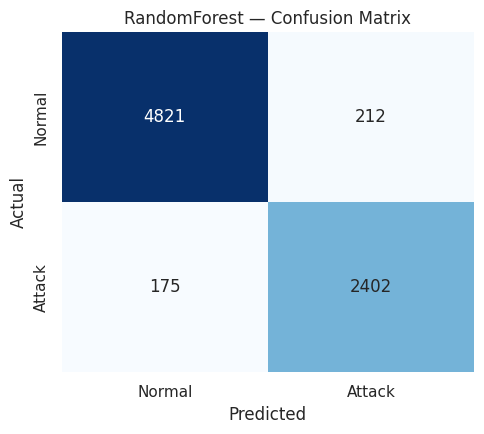

In [33]:
# Confusion matrix of the best model
cm = confusion_matrix(y_te, pt >= th)

plt.figure(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"{best} — Confusion Matrix")
plt.tight_layout(); plt.show()

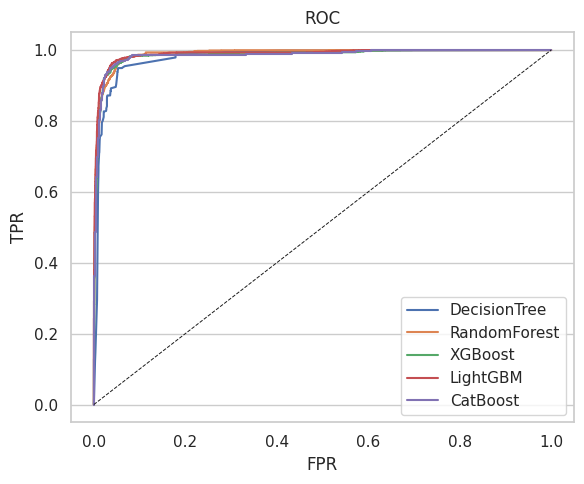

In [34]:
# ROC curve for all models
plt.figure(figsize=(6, 5))
for nm, d in probs.items():
    fpr, tpr, _ = roc_curve(y_te, d["test"])
    plt.plot(fpr, tpr, label=nm)
plt.plot([0, 1], [0, 1], "k--", lw=0.7)       # random guess line
plt.title("ROC"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend()
plt.tight_layout(); plt.show()

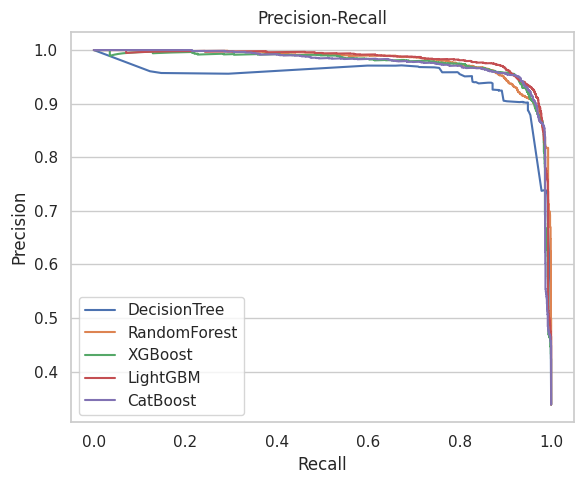

In [35]:
# Precision-Recall curve for all models
plt.figure(figsize=(6, 5))
for nm, d in probs.items():
    p, r, _ = precision_recall_curve(y_te, d["test"])
    plt.plot(r, p, label=nm)
plt.title("Precision-Recall"); plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend()
plt.tight_layout(); plt.show()

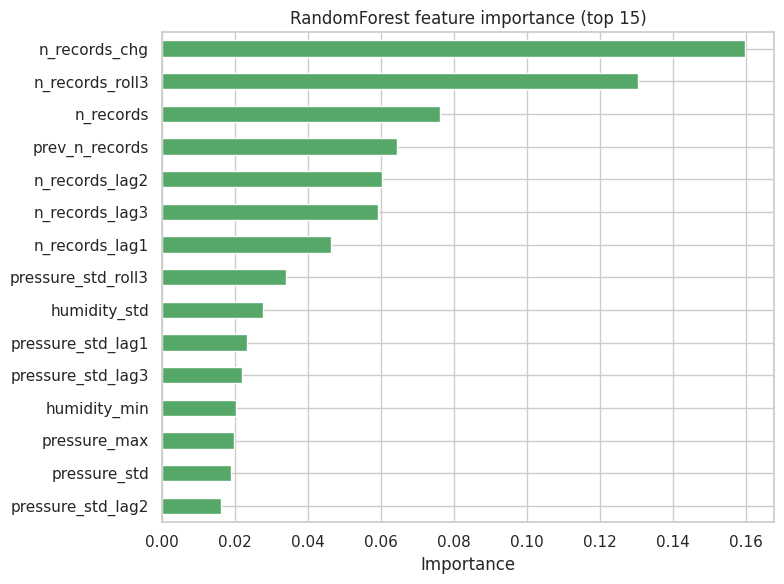

In [36]:
imp = pd.Series(models[best].feature_importances_, index=FEATURES).sort_values(ascending=False)
imp.head(15)[::-1].plot.barh(figsize=(8, 6), color="#55a868")
plt.title(f"{best} feature importance (top 15)")
plt.xlabel("Importance")
plt.tight_layout(); plt.show()

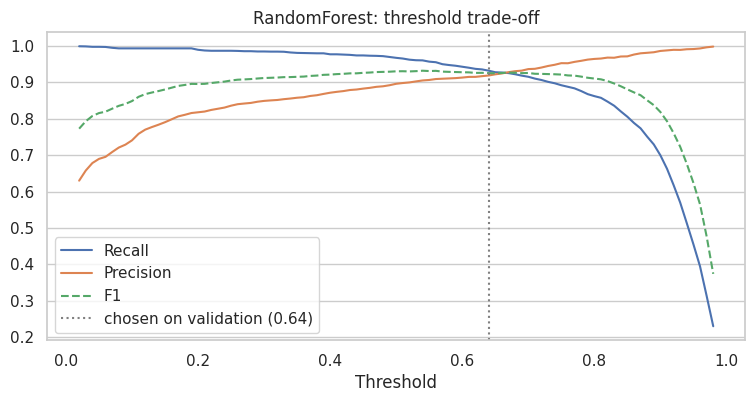

,target_recall,threshold,test_recall,test_precision,test_f1
0,0.90,0.73,0.901,0.945,0.923
1,0.95,0.59,0.946,0.912,0.928


In [37]:
ths = np.linspace(0.02, 0.98, 97)
rec = [recall_score(y_te, pt >= t) for t in ths]
pre = [precision_score(y_te, pt >= t, zero_division=1) for t in ths]
f1s = [f1_score(y_te, pt >= t) for t in ths]
plt.figure(figsize=(9, 4))
plt.plot(ths, rec, label="Recall"); plt.plot(ths, pre, label="Precision"); plt.plot(ths, f1s, label="F1", ls="--")
plt.axvline(th, color="gray", ls=":", label=f"chosen on validation ({th:.2f})")
plt.xlabel("Threshold"); plt.legend(); plt.title(f"{best}: threshold trade-off"); plt.show()

pv = probs[best]["val"]; out = []
for target in (0.90, 0.95):
    ok = [t for t in ths if recall_score(y_va, pv >= t) >= target]
    t = max(ok) if ok else ths[0]
    out.append(dict(target_recall=target, threshold=round(t, 2), test_recall=recall_score(y_te, pt >= t),
                    test_precision=precision_score(y_te, pt >= t), test_f1=f1_score(y_te, pt >= t)))
pd.DataFrame(out).round(3)

# 6) Cross-Validation

In [38]:
cv_rows = []
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (tr_i, te_i) in enumerate(outer.split(all_idx, W["type"].values, groups=block_id)):
    tr_i, te_i = tr_i[~edge[tr_i]], te_i[~edge[te_i]]
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    a, b = next(inner.split(tr_i, W["type"].values[tr_i], groups=block_id[tr_i]))
    fit_i, va_i = tr_i[a], tr_i[b]
    spw_k = (y[fit_i] == 0).sum() / (y[fit_i] == 1).sum()
    for name, m in make_models(spw_k).items():
        m = fit(name, m, X.iloc[fit_i], y[fit_i], X.iloc[va_i], y[va_i])
        th_k = best_threshold(y[va_i], m.predict_proba(X.iloc[va_i])[:, 1])
        pred = m.predict_proba(X.iloc[te_i])[:, 1] >= th_k
        cv_rows.append(dict(fold=fold, model=name, recall=recall_score(y[te_i], pred),
                            precision=precision_score(y[te_i], pred), f1=f1_score(y[te_i], pred)))
    print("fold", fold, "done")
cv_df = pd.DataFrame(cv_rows)
cv_summary = cv_df.groupby("model")[["recall", "precision", "f1"]].agg(["mean", "std"]).round(3)
cv_summary

fold 0 done
fold 1 done
fold 2 done
fold 3 done
fold 4 done


recall        precision            f1       
               mean    std      mean    std   mean    std
model                                                    
CatBoost      0.961  0.017     0.919  0.031  0.939  0.012
DecisionTree  0.922  0.020     0.895  0.054  0.908  0.032
LightGBM      0.960  0.017     0.909  0.043  0.933  0.020
RandomForest  0.957  0.015     0.907  0.019  0.931  0.012
XGBoost       0.946  0.011     0.917  0.040  0.930  0.017

# 7) Multi-Class:

In [39]:
le = LabelEncoder().fit(W["type"]); classes = list(le.classes_)
yc = le.transform(W["type"]); yc_tr, yc_va, yc_te = yc[train], yc[val], yc[test]
sw = compute_sample_weight("balanced", yc_tr)
print("Test support:", dict(pd.Series(W["type"].values[test]).value_counts()))

mc = {
    "DecisionTree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=600, learning_rate=0.07, max_depth=5, min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
                             reg_lambda=5, early_stopping_rounds=40, n_jobs=-1, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=600, learning_rate=0.07, num_leaves=31, min_child_samples=15, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, reg_lambda=5, class_weight="balanced", n_jobs=-1, random_state=SEED, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=500, learning_rate=0.1, depth=6, l2_leaf_reg=5, loss_function="MultiClass",
                                   auto_class_weights="Balanced", early_stopping_rounds=40, random_seed=SEED, verbose=0),
}
present = sorted(set(yc_te)); mc_pred, mc_rows = {}, []
for name, m in mc.items():

    m = fit(name, m, X.iloc[train], yc_tr, X.iloc[val], yc_va, sample_weight=sw if name == "XGBoost" else None)
    pred = np.asarray(m.predict(X.iloc[test])).ravel().astype(int); mc_pred[name] = pred
    mc_rows.append(dict(model=name, macro_f1=f1_score(yc_te, pred, labels=present, average="macro", zero_division=0),
                        weighted_f1=f1_score(yc_te, pred, average="weighted", zero_division=0)))
mc_results = pd.DataFrame(mc_rows).set_index("model").round(3)
mc_results

Test support: {'normal': np.int64(5033), 'backdoor': np.int64(1405), 'password': np.int64(644), 'ddos': np.int64(260), 'ransomware': np.int64(230), 'scanning': np.int64(36), 'injection': np.int64(2)}


,macro_f1,weighted_f1
model,,
DecisionTree,0.549,0.803
RandomForest,0.632,0.884
XGBoost,0.669,0.922
LightGBM,0.692,0.919
CatBoost,0.612,0.904


Best multi-class model: XGBoost


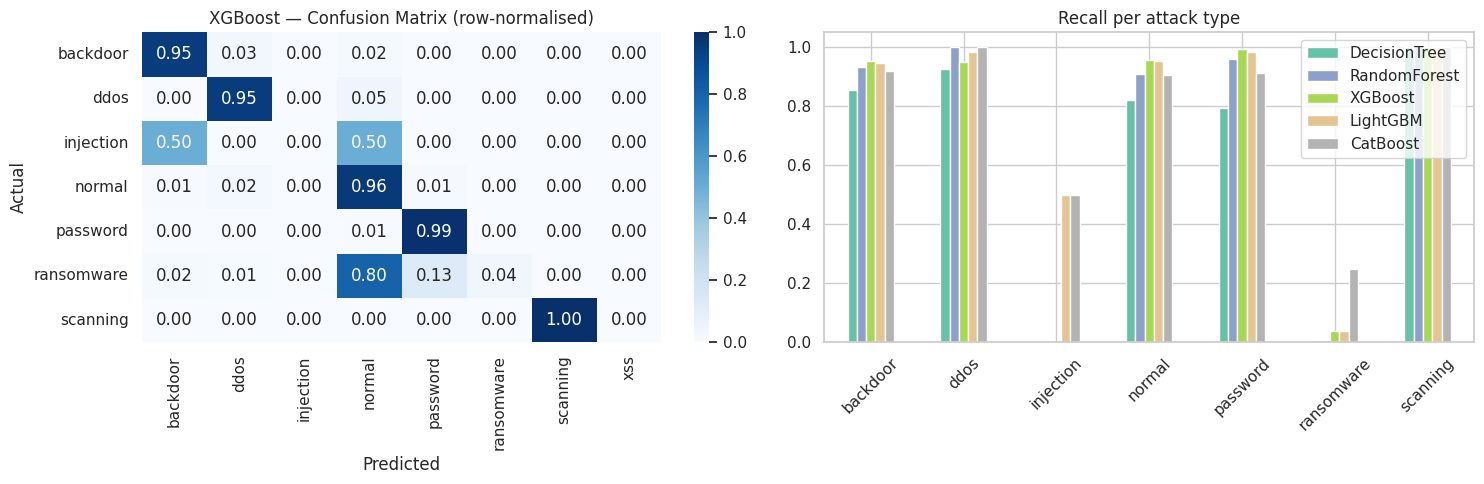

In [40]:
# choose the multi-class model by validation macro-F1 (the test set is not used for selection)
val_f1 = {n: f1_score(yc_va, np.asarray(m.predict(X.iloc[val])).ravel().astype(int),
                      labels=sorted(set(yc_va)), average="macro") for n, m in mc.items()}
best_mc = max(val_f1, key=val_f1.get); print("Best multi-class model:", best_mc)
pred = mc_pred[best_mc]

cm = confusion_matrix(yc_te, pred, labels=range(len(classes)))[present]
cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=ax[0], xticklabels=classes, yticklabels=[classes[i] for i in present])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title(f"{best_mc} — Confusion Matrix (row-normalised)")

per_class = pd.DataFrame({m: [(p[yc_te == k] == k).mean() for k in present] for m, p in mc_pred.items()},
                         index=[classes[i] for i in present])
per_class.plot.bar(ax=ax[1], rot=45, colormap="Set2"); ax[1].set_title("Recall per attack type"); ax[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

# 8) (Ablation + Random Split)

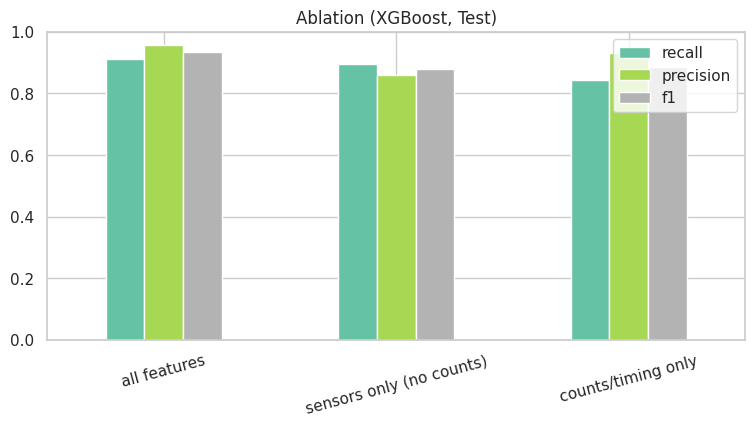

,recall,precision,f1
all features,0.912,0.956,0.933
sensors only (no counts),0.896,0.861,0.878
counts/timing only,0.844,0.930,0.885


In [41]:

TIMING = [c for c in FEATURES if "n_records" in c or c == "gap_prev"]
def quick_f1(cols):
    m = fit("XGBoost", make_models(spw)["XGBoost"], X[cols].iloc[train], y_tr, X[cols].iloc[val], y_va)
    th_ = best_threshold(y_va, m.predict_proba(X[cols].iloc[val])[:, 1])
    pr = m.predict_proba(X[cols].iloc[test])[:, 1] >= th_
    return dict(recall=recall_score(y_te, pr), precision=precision_score(y_te, pr), f1=f1_score(y_te, pr))

abl = pd.DataFrame({"all features": quick_f1(FEATURES),
                    "sensors only (no counts)": quick_f1([c for c in FEATURES if c not in TIMING]),
                    "counts/timing only": quick_f1(TIMING)}).T.round(3)
abl.plot.bar(rot=15, figsize=(9, 4), colormap="Set2"); plt.ylim(0, 1); plt.title("Ablation (XGBoost, Test)"); plt.show()
abl

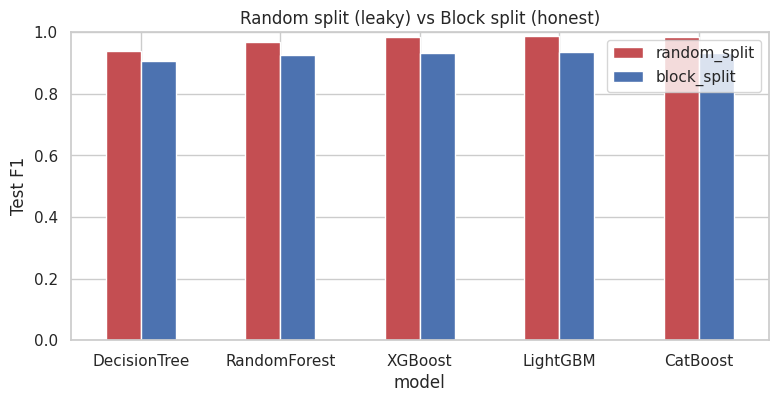

              random_split  block_split
model                                  
DecisionTree         0.939        0.906
RandomForest         0.968        0.925
XGBoost              0.984        0.933
LightGBM             0.988        0.935
CatBoost             0.984        0.932


In [42]:
a, b = train_test_split(all_idx, test_size=0.2, stratify=y, random_state=SEED)
a, v = train_test_split(a, test_size=0.2, stratify=y[a], random_state=SEED)

rows = []
for name, m in make_models(spw).items():
    m = fit(name, m, X.iloc[a], y[a], X.iloc[v], y[v])
    th_ = best_threshold(y[v], m.predict_proba(X.iloc[v])[:, 1])
    rows.append(dict(model=name,
                     random_split=f1_score(y[b], m.predict_proba(X.iloc[b])[:, 1] >= th_),

                     block_split=f1_score(y_te, probs[name]["test"] >= probs[name]["th"])))
cmp = pd.DataFrame(rows).set_index("model").round(3)
cmp.plot.bar(rot=0, figsize=(9, 4), color=["#c44e52", "#4c72b0"])
plt.ylim(0, 1); plt.ylabel("Test F1"); plt.title("Random split (leaky) vs Block split (honest)"); plt.show()
print(cmp)

In [43]:
os.makedirs("results", exist_ok=True)
results.to_csv("results/binary_results.csv"); mc_results.to_csv("results/multiclass_results.csv")
abl.to_csv("results/ablation.csv"); cv_summary.to_csv("results/cv_summary.csv"); per_class.to_csv("results/recall_per_attack_type.csv"); cmp.to_csv("results/random_vs_block.csv")
print("Saved in ./results")

Saved in ./results


In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EmpiricalCovariance
from sklearn.ensemble import IsolationForest

norm_tr = train[y[train] == 0]                      # Normal windows of the train set only

def to_percentile(raw):
    # convert a raw score to 0..1 (percentile compared with Normal train windows)
    ref = np.sort(raw[norm_tr])
    return np.searchsorted(ref, raw) / len(ref)

# 1) Z-score: average distance (in standard deviations) from the Normal mean
sc = StandardScaler().fit(X.iloc[norm_tr])
raw_z = np.abs(sc.transform(X)).mean(axis=1)

# 2) Mahalanobis: distance from the Normal distribution (uses correlation between features)
cov = EmpiricalCovariance().fit(X.iloc[norm_tr])
raw_m = cov.mahalanobis(X)

# 3) Isolation Forest
iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X.iloc[norm_tr])
raw_i = -iso.score_samples(X)

scores = {"Z-score": to_percentile(raw_z),
          "Mahalanobis": to_percentile(raw_m),
          "IsolationForest": to_percentile(raw_i)}
print("done:", list(scores))

done: ['Z-score', 'Mahalanobis', 'IsolationForest']


In [45]:
# Autoencoder anomaly score: learns to rebuild Normal windows, the reconstruction error is the score
from sklearn.neural_network import MLPRegressor

sc_ae = StandardScaler().fit(X.iloc[norm_tr])       # fit on Normal train windows only
Xn = sc_ae.transform(X.iloc[norm_tr])

ae = MLPRegressor(hidden_layer_sizes=(32, 16, 8, 16, 32), activation="relu", solver="adam",
                  max_iter=200, early_stopping=True, n_iter_no_change=10, random_state=SEED)
ae.fit(Xn, Xn)                                      # input = target

X_all = sc_ae.transform(X)
raw_ae = ((X_all - ae.predict(X_all)) ** 2).mean(axis=1)   # mean squared reconstruction error

scores["Autoencoder"] = to_percentile(raw_ae)
print("done:", list(scores))

done: ['Z-score', 'Mahalanobis', 'IsolationForest', 'Autoencoder']


In [46]:
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             recall_score, precision_score, f1_score, confusion_matrix)

ths = np.linspace(0.01, 0.99, 99)
# threshold of each model: best F1 on validation only
th_an = {nm: ths[np.argmax([f1_score(y[val], s[val] >= t) for t in ths])] for nm, s in scores.items()}

rows = []
for nm, s in scores.items():
    for split_nm, ii in (("val", val), ("test", test)):
        pred = s[ii] >= th_an[nm]
        rows.append(dict(model=nm, split=split_nm, threshold=round(th_an[nm], 2),
                         auc=roc_auc_score(y[ii], s[ii]),
                         avg_precision=average_precision_score(y[ii], s[ii]),
                         baseline_ap=y[ii].mean(),                    # AP of a random score = attack rate
                         recall=recall_score(y[ii], pred),
                         precision=precision_score(y[ii], pred, zero_division=0),
                         f1=f1_score(y[ii], pred)))
anom_results = pd.DataFrame(rows).set_index(["model", "split"]).round(3)
anom_results

threshold    auc  avg_precision  baseline_ap  recall  \
model           split                                                         
Z-score         val         0.01  0.499          0.288        0.243   0.998   
                test        0.01  0.644          0.463        0.339   0.990   
Mahalanobis     val         0.96  0.871          0.816        0.243   0.736   
                test        0.96  0.850          0.783        0.339   0.676   
IsolationForest val         0.77  0.604          0.356        0.243   0.511   
                test        0.77  0.724          0.566        0.339   0.566   
Autoencoder     val         0.93  0.846          0.722        0.243   0.657   
                test        0.93  0.841          0.754        0.339   0.651   

                       precision     f1  
model           split                    
Z-score         val        0.243  0.390  
                test       0.338  0.504  
Mahalanobis     val        0.849  0.788  
                test       0.871  0.761  
IsolationForest val        0.342  0.410  
                test       0.563  0.564  
Autoencoder     val        0.655  0.656  
                test       0.760  0.701

In [47]:
# Pick the anomaly method with the best validation F1 and keep what is needed to reuse it
best_an = anom_results.xs("val", level="split")["f1"].idxmax()
anomaly = scores[best_an]
print("Anomaly method:", best_an)

if best_an == "Mahalanobis":
    anomaly_model = {"method": best_an, "model": cov, "reference": np.sort(raw_m[norm_tr])}
elif best_an == "Autoencoder":
    anomaly_model = {"method": best_an, "model": ae, "scaler": sc_ae, "reference": np.sort(raw_ae[norm_tr])}
elif best_an == "IsolationForest":
    anomaly_model = {"method": best_an, "model": iso, "reference": np.sort(raw_i[norm_tr])}
else:
    anomaly_model = {"method": best_an, "scaler": sc, "reference": np.sort(raw_z[norm_tr])}

Anomaly method: Mahalanobis


## Final export checks

The final export cell writes the required predictions CSV and config JSON, plus the optional events CSV. It exports only train/validation/test windows (never purged windows). Both probability columns use calibrated probabilities: `p_attack` in predictions and `attack_prob` in events. The cell also reads the files back and validates column names and order.


In [48]:
# ---------- Final export: unified predictions, events, model artifact, and config ----------
import json
import os
import joblib
import numpy as np
import pandas as pd

os.makedirs("export", exist_ok=True)
os.makedirs("results", exist_ok=True)

SOURCE = "weather"
mc_best = mc[best_mc]
th_final = float(th_cal)

# Apply the same validation-fitted calibrator to every window.
# p_attack and attack_prob must use the calibrated probability scale,
# because the exported threshold was selected on calibrated validation scores.
pa = np.asarray(calibrator.predict(models[best].predict_proba(X)[:, 1]), dtype=float)
if len(pa) != len(W) or not np.isfinite(pa).all():
    raise ValueError("Calibrated attack probabilities are missing, non-finite, or have the wrong length.")

pred_type = le.inverse_transform(
    np.asarray(mc_best.predict(X)).ravel().astype(int)
)
is_attack_pred = pa >= th_final
attack_type = np.where(
    is_attack_pred,
    np.where(pred_type != "normal", pred_type, "unknown"),
    "none",
)

# Reconstruct the shared split labels. Windows removed by the 3-window
# boundary purge remain marked as 'purged' internally and are not exported.
split = np.full(len(W), "purged", dtype=object)
for idx, split_name in ((train, "train"), (val, "val"), (test, "test")):
    split[idx] = split_name

keep = split != "purged"
if not keep.any():
    raise ValueError("No windows remain after the block-boundary purge.")

# 1) Required predictions CSV: exact column names and order from the integration spec.
PREDICTION_COLUMNS = [
    "source", "chunk", "win", "split", "p_attack",
    "y_true", "true_type", "pred_type", "n_records",
]

predictions = pd.DataFrame({
    "source": SOURCE,
    "chunk": W["chunk"].to_numpy(),
    "win": W["win"].to_numpy(),
    "split": split,
    "p_attack": pa,
    "y_true": W["is_attack"].astype(int).to_numpy(),
    "true_type": W["type"].astype(str).to_numpy(),
    "pred_type": np.asarray(pred_type, dtype=str),
    "n_records": W["n_records"].astype(int).to_numpy(),
})
predictions = predictions.loc[keep, PREDICTION_COLUMNS].copy()

if (predictions["split"] == "purged").any():
    raise AssertionError("Purged windows must not appear in predictions export.")
if predictions["p_attack"].isna().any():
    raise AssertionError("p_attack contains missing values.")

predictions_path = f"export/{SOURCE}_predictions.csv"
predictions.to_csv(predictions_path, index=False)

# 2) Optional events CSV. Keep this schema identical for every device.
# Note: its probability column is named attack_prob (not p_attack).
EVENT_COLUMNS = [
    "event_id", "source", "window_start", "prediction", "attack_prob",
    "attack_type", "anomaly_score", "n_records", "true_label", "split",
]

window_start = (
    pd.Timestamp("2019-01-01")
    + pd.to_timedelta(W["win"].to_numpy() * 10, unit="s")
)
events = pd.DataFrame({
    "source": SOURCE,
    "window_start": window_start,
    "prediction": np.where(is_attack_pred, "Attack", "Normal"),
    "attack_prob": pa,
    "attack_type": attack_type,
    "anomaly_score": np.asarray(anomaly, dtype=float),
    "n_records": W["n_records"].astype(int).to_numpy(),
    "true_label": W["is_attack"].astype(int).to_numpy(),
    "split": split,
})
events = events.loc[keep].copy()
events.insert(0, "event_id", np.arange(len(events), dtype=int))
events = events[EVENT_COLUMNS]

if (events["split"] == "purged").any():
    raise AssertionError("Purged windows must not appear in events export.")
if events["attack_prob"].isna().any():
    raise AssertionError("attack_prob contains missing values.")

events_path = f"export/{SOURCE}_events.csv"
events.to_csv(events_path, index=False)
anom_results.to_csv("results/anomaly_results.csv")

# 3) Required config JSON: preserve the exact keys expected by the merger.
cfg = {
    "source": SOURCE,
    "binary_model": best,
    "multiclass_model": best_mc,
    "epoch": "2019-01-01",
    "window_seconds": 10,
    "classes": [str(c) for c in classes],
    "features": [str(c) for c in FEATURES],
    "anomaly_method": best_an,
    "calibrated": True,
    "threshold": th_final,
    "test_f1": float(f1_score(y_te, p_cal_te >= th_final)),
    "val_f1": float(f1_score(y_va, p_cal_va >= th_final)),
    "split_rule": {
        "method": "md5 hash of block number",
        "salt": SALT,
        "train_pct": TRAIN_PCT,
        "val_pct": VAL_PCT,
    },
    "block_windows": int(BLOCK),
}

CONFIG_KEYS = [
    "source", "binary_model", "multiclass_model", "epoch", "window_seconds",
    "classes", "features", "anomaly_method", "calibrated", "threshold",
    "test_f1", "val_f1", "split_rule", "block_windows",
]
assert list(cfg.keys()) == CONFIG_KEYS
config_path = f"export/{SOURCE}_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(cfg, f, indent=2, ensure_ascii=False)

# 4) Optional model artifact. It is not required for merging device exports.
model_path = f"export/{SOURCE}_model.joblib"
joblib.dump({
    "binary": models[best],
    "calibrator": calibrator,
    "multiclass": mc_best,
    "label_encoder": le,
    "anomaly": anomaly_model,
}, model_path)

# 5) Read-back checks: catch accidental schema/order changes before handoff.
check_predictions = pd.read_csv(predictions_path)
check_events = pd.read_csv(events_path)
with open(config_path, encoding="utf-8") as f:
    check_cfg = json.load(f)

assert check_predictions.columns.tolist() == PREDICTION_COLUMNS
assert check_events.columns.tolist() == EVENT_COLUMNS
assert set(check_predictions["split"].unique()).issubset({"train", "val", "test"})
assert set(check_events["split"].unique()).issubset({"train", "val", "test"})
assert list(check_cfg.keys()) == CONFIG_KEYS
assert check_cfg["source"] == SOURCE

print("Export completed successfully")
print("Predictions:", predictions_path, predictions.shape, predictions.columns.tolist())
print("Events:", events_path, events.shape, events.columns.tolist())
print("Config:", config_path)
print("Optional model artifact:", model_path)
print("Split counts:", predictions["split"].value_counts().to_dict())
print("Calibrated threshold:", round(th_final, 4), "| Test F1:", round(cfg["test_f1"], 3))
events.head()


Export completed successfully
Predictions: export/weather_predictions.csv (51610, 9) ['source', 'chunk', 'win', 'split', 'p_attack', 'y_true', 'true_type', 'pred_type', 'n_records']
Events: export/weather_events.csv (51610, 10) ['event_id', 'source', 'window_start', 'prediction', 'attack_prob', 'attack_type', 'anomaly_score', 'n_records', 'true_label', 'split']
Config: export/weather_config.json
Optional model artifact: export/weather_model.joblib
Split counts: {'train': 36606, 'test': 7610, 'val': 7394}
Calibrated threshold: 0.44 | Test F1: 0.926


,event_id,source,window_start,prediction,attack_prob,attack_type,anomaly_score,n_records,true_label,split
2,0,weather,2019-03-31 12:37:10,Normal,0.081633,none,0.999883,51,0,train
3,1,weather,2019-03-31 12:37:20,Normal,0.014230,none,0.989296,71,0,train
4,2,weather,2019-03-31 12:37:30,Normal,0.014230,none,0.985936,91,0,train
5,3,weather,2019-03-31 12:37:40,Normal,0.014230,none,0.978201,111,0,train
6,4,weather,2019-03-31 12:37:50,Normal,0.003300,none,0.974372,131,0,train


# 10) Classical models: LR, LDA, kNN, NB, SVM (RBF)
**CART and RF are not repeated here**: they are the same as `DecisionTree` and `RandomForest` above (same settings), so we keep one version only.
These 5 models are added **on top of** the 5 models above. They use the same split (`train / val / test`), the same features and the same rules:
threshold chosen on **validation only**, test used once for reporting. Results are kept in **separate DataFrames** (names start with `classic_`), so nothing above is changed.

In [ ]:
# ---------- 10.1 Setup: models + helper functions ----------
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
                             average_precision_score, classification_report)

SVM_MAX_TRAIN = None   # SVM (RBF) can be slow on big data: put e.g. 20000 to train it on a stratified sample
RUN_CV = False         # True = also run block cross-validation for the 5 models (slow, mostly because of SVM)

def make_classic_models():
    return {
        # LR, kNN and SVM depend on feature scale, so they get a StandardScaler inside a pipeline
        # (the scaler is fitted on the training data only, so there is no leakage)
        "LR":        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        "LDA":       LinearDiscriminantAnalysis(),
        "kNN":       make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, n_jobs=-1)),
        "NB":        GaussianNB(),
        "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED)),
    }

def c_fit_idx(name):
    """Rows used for training (optionally a stratified sample for the SVM)."""
    if name == "SVM (RBF)" and SVM_MAX_TRAIN and len(train) > SVM_MAX_TRAIN:
        _, idx = train_test_split(train, test_size=SVM_MAX_TRAIN, stratify=y[train], random_state=SEED)
        return np.sort(idx)
    return train

def c_score(m, Xs):
    """Attack score: probability if the model has one, otherwise the SVM decision function."""
    return m.predict_proba(Xs)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xs)

def c_best_threshold(y_true, s):
    """Best-F1 threshold on validation. Works for probabilities and for SVM decision scores."""
    cands = np.unique(np.quantile(s, np.linspace(0.01, 0.99, 197)))
    return cands[int(np.argmax([f1_score(y_true, s >= t) for t in cands]))]

def c_bin_metrics(y_true, s, th):
    pred = (s >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(threshold=th,
                accuracy=accuracy_score(y_true, pred),
                balanced_acc=balanced_accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred),
                specificity=tn / max(tn + fp, 1),
                f1=f1_score(y_true, pred),
                FPR=fp / max(fp + tn, 1),
                FNR=fn / max(fn + tp, 1),
                MCC=matthews_corrcoef(y_true, pred),
                kappa=cohen_kappa_score(y_true, pred),
                roc_auc=roc_auc_score(y_true, s),
                pr_auc=average_precision_score(y_true, s),
                TN=tn, FP=fp, FN=fn, TP=tp)
print("setup done")

## 10.2 Binary (Normal vs Attack): train all 5 models

In [ ]:
# ---------- 10.2 Binary training + full evaluation on train / val / test ----------
classic_models, classic_scores, bin_rows = {}, {}, []
for name, m in make_classic_models().items():
    t0 = time.time()
    idx = c_fit_idx(name)
    m.fit(X.iloc[idx], y[idx])
    s = {sp: c_score(m, X.iloc[ii]) for sp, ii in (("train", train), ("val", val), ("test", test))}
    th = c_best_threshold(y_va, s["val"])                      # threshold chosen on validation only
    classic_models[name], classic_scores[name] = m, dict(**s, th=th)
    for sp, yt in (("train", y_tr), ("val", y_va), ("test", y_te)):
        bin_rows.append(dict(model=name, split=sp, **c_bin_metrics(yt, s[sp], th)))
    print(f"{name:10s} done in {time.time() - t0:5.1f}s")

classic_bin_results = pd.DataFrame(bin_rows).set_index(["model", "split"])
INT_COLS = ["TN", "FP", "FN", "TP"]
classic_bin_results[INT_COLS] = classic_bin_results[INT_COLS].astype(int)
classic_bin_results.round(3)

In [ ]:
# Test-set table (sorted by F1) + overfitting gap (train F1 - test F1)
classic_bin_test = classic_bin_results.xs("test", level="split").drop(columns=INT_COLS).sort_values("f1", ascending=False)
classic_bin_test["f1_gap (train-test)"] = (classic_bin_results.xs("train", level="split")["f1"]
                                           - classic_bin_results.xs("test", level="split")["f1"])
classic_bin_test.round(3)

In [ ]:
# Confusion matrix (counts) for every model, on the test set
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, (name, d) in zip(axes, classic_scores.items()):
    cm_ = confusion_matrix(y_te, d["test"] >= d["th"], labels=[0, 1])
    sns.heatmap(cm_, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for ax in axes[len(classic_scores):]: ax.axis("off")
plt.suptitle("Binary confusion matrices (test)"); plt.tight_layout(); plt.show()

In [ ]:
# ROC + Precision-Recall curves for the 5 models (test)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nm, d in classic_scores.items():
    fpr, tpr, _ = roc_curve(y_te, d["test"]);            ax[0].plot(fpr, tpr, label=f"{nm} (AUC={roc_auc_score(y_te, d['test']):.3f})")
    p_, r_, _ = precision_recall_curve(y_te, d["test"]); ax[1].plot(r_, p_, label=f"{nm} (AP={average_precision_score(y_te, d['test']):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.7); ax[0].set_title("ROC"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ax[1].axhline(y_te.mean(), color="k", ls="--", lw=0.7); ax[1].set_title("Precision-Recall"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Threshold trade-off (recall / precision / F1) for every model + metrics bar chart
fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, (name, d) in zip(axes, classic_scores.items()):
    tt = np.unique(np.quantile(d["test"], np.linspace(0.01, 0.99, 120)))
    ax.plot(tt, [recall_score(y_te, d["test"] >= t) for t in tt], label="Recall")
    ax.plot(tt, [precision_score(y_te, d["test"] >= t, zero_division=1) for t in tt], label="Precision")
    ax.plot(tt, [f1_score(y_te, d["test"] >= t) for t in tt], "--", label="F1")
    ax.axvline(d["th"], color="gray", ls=":", label="chosen (val)"); ax.set_title(name)
axes[0].legend(fontsize=8)
for ax in axes[len(classic_scores):]: ax.axis("off")
plt.tight_layout(); plt.show()

classic_bin_test[["accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc", "pr_auc", "MCC"]].plot.bar(
    figsize=(12, 4), rot=0, colormap="Set2"); plt.ylim(0, 1.05); plt.title("Binary metrics on test"); plt.legend(ncol=4, fontsize=8); plt.show()

In [ ]:
# Feature importance / coefficients (RF and CART = the original RandomForest / DecisionTree from section 4)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a_, nm in zip(ax[:2], ("RandomForest", "DecisionTree")):
    pd.Series(models[nm].feature_importances_, index=FEATURES).sort_values().tail(15).plot.barh(ax=a_, color="#55a868")
    a_.set_title(f"{nm} feature importance (top 15)")
coef = pd.Series(classic_models["LR"][-1].coef_[0], index=FEATURES)
coef.reindex(coef.abs().sort_values().tail(15).index).plot.barh(ax=ax[2], color="#4c72b0")
ax[2].set_title("LR coefficients (top 15 by size, features scaled)")
plt.tight_layout(); plt.show()

## 10.3 Multi-class (attack type): train all 5 models

In [ ]:
# ---------- 10.3 Multi-class training + full evaluation ----------
def c_mc_proba(m, Xs):
    """Probability matrix with one column per class in `classes` (None if the model has no probabilities)."""
    if not hasattr(m, "predict_proba"): return None
    P = np.zeros((len(Xs), len(classes))); P[:, np.asarray(m.classes_, dtype=int)] = m.predict_proba(Xs)
    return P

def c_mc_metrics(y_true, pred, P=None):
    lab = sorted(set(y_true))                                  # only classes that exist in this split
    row = dict(accuracy=accuracy_score(y_true, pred),
               balanced_acc=balanced_accuracy_score(y_true, pred),
               macro_precision=precision_score(y_true, pred, labels=lab, average="macro", zero_division=0),
               macro_recall=recall_score(y_true, pred, labels=lab, average="macro", zero_division=0),
               macro_f1=f1_score(y_true, pred, labels=lab, average="macro", zero_division=0),
               weighted_precision=precision_score(y_true, pred, average="weighted", zero_division=0),
               weighted_recall=recall_score(y_true, pred, average="weighted", zero_division=0),
               weighted_f1=f1_score(y_true, pred, average="weighted", zero_division=0),
               MCC=matthews_corrcoef(y_true, pred), kappa=cohen_kappa_score(y_true, pred), roc_auc_ovr=np.nan)
    if P is not None and len(lab) > 2:                         # macro one-vs-rest AUC (needs probabilities)
        Ps = P[:, lab]; Ps = Ps / np.maximum(Ps.sum(axis=1, keepdims=True), 1e-12)
        try: row["roc_auc_ovr"] = roc_auc_score(y_true, Ps, multi_class="ovr", average="macro", labels=lab)
        except ValueError: pass
    return row

classic_mc_models, classic_mc_pred, mc_rows, pc_rows = {}, {}, [], []
for name, m in make_classic_models().items():
    t0 = time.time()
    idx = c_fit_idx(name)
    m.fit(X.iloc[idx], yc[idx])
    classic_mc_models[name] = m
    for sp, ii, yt in (("train", train, yc_tr), ("val", val, yc_va), ("test", test, yc_te)):
        pr_ = np.asarray(m.predict(X.iloc[ii])).ravel().astype(int)
        if sp == "test": classic_mc_pred[name] = pr_
        mc_rows.append(dict(model=name, split=sp, **c_mc_metrics(yt, pr_, c_mc_proba(m, X.iloc[ii]))))
    # per-class precision / recall / F1 / support on test
    rep = classification_report(yc_te, classic_mc_pred[name], labels=present, target_names=[classes[i] for i in present],
                                output_dict=True, zero_division=0)
    for cl in [classes[i] for i in present]:
        pc_rows.append(dict(model=name, **{"class": cl}, **{k: rep[cl][k] for k in ("precision", "recall", "f1-score", "support")}))
    print(f"{name:10s} done in {time.time() - t0:5.1f}s")

classic_mc_results = pd.DataFrame(mc_rows).set_index(["model", "split"])
classic_mc_results.round(3)

In [ ]:
# Test-set multi-class table + per-class table
classic_mc_test = classic_mc_results.xs("test", level="split").sort_values("macro_f1", ascending=False)
classic_mc_test["macro_f1_gap (train-test)"] = (classic_mc_results.xs("train", level="split")["macro_f1"]
                                                - classic_mc_results.xs("test", level="split")["macro_f1"])
classic_per_class = pd.DataFrame(pc_rows).set_index(["model", "class"])
display(classic_mc_test.round(3))
classic_per_class.round(3)

In [ ]:
# Per-class recall + row-normalised confusion matrices for the 5 models (test)
cls_names = [classes[i] for i in present]
classic_recall = classic_per_class["recall"].unstack("model")[list(classic_mc_models)].loc[cls_names]
classic_recall.plot.bar(figsize=(12, 4), rot=45, colormap="Set2"); plt.ylim(0, 1.05); plt.title("Recall per attack type (test)"); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(24, 10)); axes = axes.ravel()
for ax, (name, pr_) in zip(axes, classic_mc_pred.items()):
    cm_ = confusion_matrix(yc_te, pr_, labels=range(len(classes)))[present]
    cm_ = cm_ / np.maximum(cm_.sum(axis=1, keepdims=True), 1)
    sns.heatmap(cm_, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax, xticklabels=classes, yticklabels=cls_names)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for ax in axes[len(classic_mc_pred):]: ax.axis("off")
plt.suptitle("Multi-class confusion matrices (row-normalised, test)"); plt.tight_layout(); plt.show()

## 10.4 Optional: block cross-validation (set `RUN_CV = True` in cell 10.1)

In [ ]:
# ---------- 10.4 Block cross-validation for the 5 models (same folds / rules as section 6) ----------
if RUN_CV:
    cv_rows_c = []
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (tr_i, te_i) in enumerate(outer.split(all_idx, W["type"].values, groups=block_id)):
        tr_i, te_i = tr_i[~edge[tr_i]], te_i[~edge[te_i]]
        inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        a_, b_ = next(inner.split(tr_i, W["type"].values[tr_i], groups=block_id[tr_i]))
        fit_i, va_i = tr_i[a_], tr_i[b_]
        for name, m in make_classic_models().items():
            m.fit(X.iloc[fit_i], y[fit_i])
            th_k = c_best_threshold(y[va_i], c_score(m, X.iloc[va_i]))
            s_te = c_score(m, X.iloc[te_i]); pred = s_te >= th_k
            cv_rows_c.append(dict(fold=fold, model=name, recall=recall_score(y[te_i], pred),
                                  precision=precision_score(y[te_i], pred, zero_division=0),
                                  f1=f1_score(y[te_i], pred), roc_auc=roc_auc_score(y[te_i], s_te),
                                  MCC=matthews_corrcoef(y[te_i], pred)))
        print("fold", fold, "done")
    classic_cv_df = pd.DataFrame(cv_rows_c)
    classic_cv_summary = classic_cv_df.groupby("model")[["recall", "precision", "f1", "roc_auc", "MCC"]].agg(["mean", "std"]).round(3)
    display(classic_cv_summary)
else:
    print("Skipped (RUN_CV = False)")

## 10.5 Final DataFrames (separate from the first 5 models)

In [ ]:
# ---------- 10.5 Final tables + save ----------
# One summary table: binary + multi-class on test, for the 5 classic models only
classic_summary = (classic_bin_test[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "MCC"]].add_prefix("bin_")
                   .join(classic_mc_test[["accuracy", "balanced_acc", "macro_f1", "weighted_f1", "MCC"]].add_prefix("mc_"))
                   .sort_values("bin_f1", ascending=False))
os.makedirs("results", exist_ok=True)
classic_bin_results.to_csv("results/classic_binary_results.csv")
classic_mc_results.to_csv("results/classic_multiclass_results.csv")
classic_per_class.to_csv("results/classic_per_class.csv")
classic_summary.to_csv("results/classic_summary.csv")
if RUN_CV: classic_cv_summary.to_csv("results/classic_cv_summary.csv")
print("Saved in ./results (files start with classic_)")
classic_summary.round(3)

# 11) Improve the classic models + choose the best model from ALL models
1. **Tuning:** each classic model gets a small grid (scaler + main hyper-parameters). The best setting is chosen on **validation only** (binary: F1, multi-class: macro-F1). The test set is not used for tuning.
2. **One version only:** CART and RF are the `DecisionTree` and `RandomForest` from section 4, so they are not repeated.
3. **Final leaderboard:** the 5 original models + the 5 tuned classic models, in separate DataFrames, and the best model for binary and for multi-class is picked by validation score.

In [ ]:
# ---------- 11.1 Tuning grids ----------
from sklearn.preprocessing import QuantileTransformer
from sklearn.model_selection import ParameterGrid

def make_scaler(kind):
    # "quantile" makes skewed features (n_records, pressure ...) look normal, which helps LR / LDA / NB / kNN / SVM
    return StandardScaler() if kind == "standard" else QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=SEED)

def build_tuned(name, p):
    sc_ = make_scaler(p["scaler"])
    if name == "LR":          est = LogisticRegression(C=p["C"], max_iter=3000, class_weight="balanced", random_state=SEED)
    elif name == "LDA":       est = LinearDiscriminantAnalysis(solver="lsqr", shrinkage=p["shrinkage"])   # shrinkage helps with correlated lag features
    elif name == "kNN":       est = KNeighborsClassifier(n_neighbors=p["k"], weights="distance", n_jobs=-1)
    elif name == "NB":        est = GaussianNB(var_smoothing=p["var_smoothing"])
    elif name == "SVM (RBF)": est = SVC(kernel="rbf", C=p["C"], gamma="scale", class_weight="balanced", random_state=SEED)
    return make_pipeline(sc_, est)

SCALERS = ["standard", "quantile"]
TUNE_GRID = {
    "LR":        dict(scaler=SCALERS, C=[0.1, 1, 10]),
    "LDA":       dict(scaler=SCALERS, shrinkage=[None, "auto"]),
    "kNN":       dict(scaler=SCALERS, k=[5, 15, 31]),
    "NB":        dict(scaler=SCALERS, var_smoothing=[1e-9, 1e-6, 1e-3]),
    "SVM (RBF)": dict(scaler=SCALERS, C=[1, 10]),          # SVM is the slow one: 4 fits for binary + 4 for multi-class
}
print({k: len(list(ParameterGrid(v))) for k, v in TUNE_GRID.items()}, "settings per model")

## 11.2 Tuning for the binary task (best validation F1)

In [ ]:
# ---------- 11.2 Binary tuning ----------
tuned_bin, tune_rows = {}, []
for name, grid in TUNE_GRID.items():
    t0, best_f1 = time.time(), -1
    for p in ParameterGrid(grid):
        m = build_tuned(name, p); idx = c_fit_idx(name)
        m.fit(X.iloc[idx], y[idx])
        s_va = c_score(m, X.iloc[val]); f1v = f1_score(y_va, s_va >= c_best_threshold(y_va, s_va))
        tune_rows.append(dict(task="binary", model=name, **p, val_score=f1v))
        if f1v > best_f1: best_f1, tuned_bin[name] = f1v, (m, p)
    print(f"{name:10s} best val F1 = {best_f1:.3f}  {tuned_bin[name][1]}  ({time.time() - t0:.0f}s)")

## 11.3 Tuning for the multi-class task (best validation macro-F1)

In [ ]:
# ---------- 11.3 Multi-class tuning ----------
tuned_mc = {}
lab_va = sorted(set(yc_va))
for name, grid in TUNE_GRID.items():
    t0, best_f1 = time.time(), -1
    for p in ParameterGrid(grid):
        m = build_tuned(name, p); idx = c_fit_idx(name)
        m.fit(X.iloc[idx], yc[idx])
        pr_ = np.asarray(m.predict(X.iloc[val])).ravel().astype(int)
        f1v = f1_score(yc_va, pr_, labels=lab_va, average="macro", zero_division=0)
        tune_rows.append(dict(task="multiclass", model=name, **p, val_score=f1v))
        if f1v > best_f1: best_f1, tuned_mc[name] = f1v, (m, p)
    print(f"{name:10s} best val macro-F1 = {best_f1:.3f}  {tuned_mc[name][1]}  ({time.time() - t0:.0f}s)")

classic_tuning_log = pd.DataFrame(tune_rows)          # every setting that was tried
classic_best_params = pd.DataFrame([dict(task="binary", model=n, **p) for n, (m, p) in tuned_bin.items()]
                                   + [dict(task="multiclass", model=n, **p) for n, (m, p) in tuned_mc.items()])
classic_best_params

## 11.4 Before vs after tuning (test) — classic models only

In [ ]:
# ---------- 11.4 Tuned classic models: full evaluation (train / val / test) ----------
tuned_bin_scores, tuned_bin_rows = {}, []
for name, (m, p) in tuned_bin.items():
    s = {sp: c_score(m, X.iloc[ii]) for sp, ii in (("train", train), ("val", val), ("test", test))}
    th = c_best_threshold(y_va, s["val"]); tuned_bin_scores[name] = dict(**s, th=th)
    for sp, yt in (("train", y_tr), ("val", y_va), ("test", y_te)):
        tuned_bin_rows.append(dict(model=name, split=sp, **c_bin_metrics(yt, s[sp], th)))
tuned_bin_results = pd.DataFrame(tuned_bin_rows).set_index(["model", "split"])
tuned_bin_results[INT_COLS] = tuned_bin_results[INT_COLS].astype(int)

tuned_mc_rows, tuned_mc_pred = [], {}
for name, (m, p) in tuned_mc.items():
    for sp, ii, yt in (("train", train, yc_tr), ("val", val, yc_va), ("test", test, yc_te)):
        pr_ = np.asarray(m.predict(X.iloc[ii])).ravel().astype(int)
        if sp == "test": tuned_mc_pred[name] = pr_
        tuned_mc_rows.append(dict(model=name, split=sp, **c_mc_metrics(yt, pr_, c_mc_proba(m, X.iloc[ii]))))
tuned_mc_results = pd.DataFrame(tuned_mc_rows).set_index(["model", "split"])

classic_before_after = pd.concat({
    "binary F1 (before)":      classic_bin_results.xs("test", level="split")["f1"],
    "binary F1 (after)":       tuned_bin_results.xs("test", level="split")["f1"],
    "binary ROC-AUC (before)": classic_bin_results.xs("test", level="split")["roc_auc"],
    "binary ROC-AUC (after)":  tuned_bin_results.xs("test", level="split")["roc_auc"],
    "multi macro-F1 (before)": classic_mc_results.xs("test", level="split")["macro_f1"],
    "multi macro-F1 (after)":  tuned_mc_results.xs("test", level="split")["macro_f1"],
}, axis=1).round(3)
classic_before_after

## 11.5 Leaderboard: all models together + best model

In [ ]:
# ---------- 11.5 Binary leaderboard: 5 original models + 5 tuned classic models ----------
all_bin_models = {**models, **{n: m for n, (m, p) in tuned_bin.items()}}
all_bin_scores = {**{n: probs[n] for n in models}, **tuned_bin_scores}
source_of = {**{n: "original (sec. 4)" for n in models}, **{n: "classic (tuned)" for n in tuned_bin}}

lb_rows = []
for name, d in all_bin_scores.items():
    r_va, r_te = c_bin_metrics(y_va, d["val"], d["th"]), c_bin_metrics(y_te, d["test"], d["th"])
    lb_rows.append(dict(model=name, source=source_of[name], val_f1=r_va["f1"],
                        **{f"test_{k}": r_te[k] for k in ("accuracy", "balanced_acc", "precision", "recall", "specificity",
                                                         "f1", "MCC", "roc_auc", "pr_auc", "FPR", "FNR")}))
all_bin_leaderboard = pd.DataFrame(lb_rows).set_index("model").sort_values("val_f1", ascending=False)
best_bin_name = all_bin_leaderboard.index[0]                         # chosen by VALIDATION F1
print("Best binary model (validation F1):", best_bin_name)
all_bin_leaderboard.round(3)

In [ ]:
# ---------- Multi-class leaderboard: 5 original models + 5 tuned classic models ----------
all_mc_models = {**mc, **{n: m for n, (m, p) in tuned_mc.items()}}
src_mc = {**{n: "original (sec. 7)" for n in mc}, **{n: "classic (tuned)" for n in tuned_mc}}

def c_mc_proba_safe(m, Xs):
    try: return c_mc_proba(m, Xs)
    except Exception: return None

lb_rows, all_mc_test_pred = [], {}
for name, m in all_mc_models.items():
    pv = np.asarray(m.predict(X.iloc[val])).ravel().astype(int)
    pt_ = np.asarray(m.predict(X.iloc[test])).ravel().astype(int); all_mc_test_pred[name] = pt_
    r_va = c_mc_metrics(yc_va, pv)
    r_te = c_mc_metrics(yc_te, pt_, c_mc_proba_safe(m, X.iloc[test]))
    lb_rows.append(dict(model=name, source=src_mc[name], val_macro_f1=r_va["macro_f1"], **{f"test_{k}": v for k, v in r_te.items()}))
all_mc_leaderboard = pd.DataFrame(lb_rows).set_index("model").sort_values("val_macro_f1", ascending=False)
best_mc_name = all_mc_leaderboard.index[0]                           # chosen by VALIDATION macro-F1
print("Best multi-class model (validation macro-F1):", best_mc_name)
all_mc_leaderboard.round(3)

In [ ]:
# ---------- Full evaluation of the two best models ----------
print(f"BEST BINARY MODEL: {best_bin_name}   |   BEST MULTI-CLASS MODEL: {best_mc_name}\n")
d = all_bin_scores[best_bin_name]
best_bin_full = pd.DataFrame({sp: c_bin_metrics(yt, d[sp], d["th"]) for sp, yt in (("train", y_tr), ("val", y_va), ("test", y_te))}).T
display(best_bin_full.round(3))

fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
sns.heatmap(confusion_matrix(y_te, d["test"] >= d["th"]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"]); ax[0].set_title(f"{best_bin_name}: binary (test)")
for nm, dd in all_bin_scores.items():
    fpr, tpr, _ = roc_curve(y_te, dd["test"]); ax[1].plot(fpr, tpr, lw=2.5 if nm == best_bin_name else 1, label=nm)
    p_, r_, _ = precision_recall_curve(y_te, dd["test"]); ax[2].plot(r_, p_, lw=2.5 if nm == best_bin_name else 1, label=nm)
ax[1].plot([0, 1], [0, 1], "k--", lw=0.7); ax[1].set_title("ROC (all models)"); ax[1].legend(fontsize=7)
ax[2].set_title("Precision-Recall (all models)")
cm_ = confusion_matrix(yc_te, all_mc_test_pred[best_mc_name], labels=range(len(classes)))[present]
cm_ = cm_ / np.maximum(cm_.sum(axis=1, keepdims=True), 1)
sns.heatmap(cm_, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[3], xticklabels=classes, yticklabels=[classes[i] for i in present])
ax[3].set_title(f"{best_mc_name}: multi-class (row-normalised, test)"); plt.tight_layout(); plt.show()

best_mc_report = pd.DataFrame(classification_report(yc_te, all_mc_test_pred[best_mc_name], labels=present,
                              target_names=[classes[i] for i in present], output_dict=True, zero_division=0)).T.round(3)
best_mc_report

# 12) Export files for the best model (binary + multi-class)
Same files and column order as the export in section 9, but built from the **best model of the leaderboard** (`best_bin_name`, `best_mc_name`).
Everything is written to the folder `export_best/` so the first export is not overwritten. The probability is calibrated on **validation only** and the threshold is chosen on the calibrated validation scores.

In [ ]:
# ---------- 12) Export for the best model ----------
import json, joblib
from sklearn.isotonic import IsotonicRegression

os.makedirs("export_best", exist_ok=True); os.makedirs("results", exist_ok=True)
SOURCE = "weather"
bin_best_model, mc_best_model = all_bin_models[best_bin_name], all_mc_models[best_mc_name]

# calibration + threshold: validation only
cal_best = IsotonicRegression(out_of_bounds="clip").fit(all_bin_scores[best_bin_name]["val"], y_va)
p_cal_va_b = cal_best.predict(all_bin_scores[best_bin_name]["val"])
p_cal_te_b = cal_best.predict(all_bin_scores[best_bin_name]["test"])
th_best = float(c_best_threshold(y_va, p_cal_va_b))

pa_b = np.asarray(cal_best.predict(c_score(bin_best_model, X)), dtype=float)         # calibrated p(attack) for every window
if len(pa_b) != len(W) or not np.isfinite(pa_b).all():
    raise ValueError("Calibrated probabilities are missing, non-finite, or have the wrong length.")

pred_type_b = le.inverse_transform(np.asarray(mc_best_model.predict(X)).ravel().astype(int))
is_attack_b = pa_b >= th_best
attack_type_b = np.where(is_attack_b, np.where(pred_type_b != "normal", pred_type_b, "unknown"), "none")

split_b = np.full(len(W), "purged", dtype=object)
for idx_, nm_ in ((train, "train"), (val, "val"), (test, "test")): split_b[idx_] = nm_
keep_b = split_b != "purged"

PREDICTION_COLUMNS = ["source", "chunk", "win", "split", "p_attack", "y_true", "true_type", "pred_type", "n_records"]
predictions_best = pd.DataFrame({"source": SOURCE, "chunk": W["chunk"].to_numpy(), "win": W["win"].to_numpy(), "split": split_b,
                                 "p_attack": pa_b, "y_true": W["is_attack"].astype(int).to_numpy(),
                                 "true_type": W["type"].astype(str).to_numpy(), "pred_type": np.asarray(pred_type_b, dtype=str),
                                 "n_records": W["n_records"].astype(int).to_numpy()}).loc[keep_b, PREDICTION_COLUMNS].copy()
predictions_best.to_csv(f"export_best/{SOURCE}_predictions.csv", index=False)

EVENT_COLUMNS = ["event_id", "source", "window_start", "prediction", "attack_prob", "attack_type", "anomaly_score",
                 "n_records", "true_label", "split"]
events_best = pd.DataFrame({"source": SOURCE,
                            "window_start": pd.Timestamp("2019-01-01") + pd.to_timedelta(W["win"].to_numpy() * 10, unit="s"),
                            "prediction": np.where(is_attack_b, "Attack", "Normal"), "attack_prob": pa_b,
                            "attack_type": attack_type_b, "anomaly_score": np.asarray(anomaly, dtype=float),
                            "n_records": W["n_records"].astype(int).to_numpy(), "true_label": W["is_attack"].astype(int).to_numpy(),
                            "split": split_b}).loc[keep_b].copy()
events_best.insert(0, "event_id", np.arange(len(events_best), dtype=int))
events_best = events_best[EVENT_COLUMNS]
events_best.to_csv(f"export_best/{SOURCE}_events.csv", index=False)

CONFIG_KEYS = ["source", "binary_model", "multiclass_model", "epoch", "window_seconds", "classes", "features", "anomaly_method",
               "calibrated", "threshold", "test_f1", "val_f1", "split_rule", "block_windows"]
cfg_best = {"source": SOURCE, "binary_model": best_bin_name, "multiclass_model": best_mc_name, "epoch": "2019-01-01",
            "window_seconds": 10, "classes": [str(c) for c in classes], "features": [str(c) for c in FEATURES],
            "anomaly_method": best_an, "calibrated": True, "threshold": th_best,
            "test_f1": float(f1_score(y_te, p_cal_te_b >= th_best)), "val_f1": float(f1_score(y_va, p_cal_va_b >= th_best)),
            "split_rule": {"method": "md5 hash of block number", "salt": SALT, "train_pct": TRAIN_PCT, "val_pct": VAL_PCT},
            "block_windows": int(BLOCK)}
assert list(cfg_best.keys()) == CONFIG_KEYS
with open(f"export_best/{SOURCE}_config.json", "w", encoding="utf-8") as f: json.dump(cfg_best, f, indent=2, ensure_ascii=False)

joblib.dump({"binary": bin_best_model, "calibrator": cal_best, "multiclass": mc_best_model, "label_encoder": le,
             "anomaly": anomaly_model}, f"export_best/{SOURCE}_model.joblib")

# the leaderboards and tuning tables are saved too
all_bin_leaderboard.to_csv("results/all_models_binary_leaderboard.csv"); all_mc_leaderboard.to_csv("results/all_models_multiclass_leaderboard.csv")
classic_before_after.to_csv("results/classic_before_after_tuning.csv"); classic_best_params.to_csv("results/classic_best_params.csv")
classic_tuning_log.to_csv("results/classic_tuning_log.csv"); best_bin_full.to_csv("results/best_binary_model_full_eval.csv")
best_mc_report.to_csv("results/best_multiclass_model_report.csv")

# read-back checks
chk_p, chk_e = pd.read_csv(f"export_best/{SOURCE}_predictions.csv"), pd.read_csv(f"export_best/{SOURCE}_events.csv")
assert chk_p.columns.tolist() == PREDICTION_COLUMNS and chk_e.columns.tolist() == EVENT_COLUMNS
assert set(chk_p["split"]) <= {"train", "val", "test"} and set(chk_e["split"]) <= {"train", "val", "test"}
print("Export completed in ./export_best")
print("Binary:", best_bin_name, "| Multi-class:", best_mc_name, "| threshold:", round(th_best, 4),
      "| val F1:", round(cfg_best["val_f1"], 3), "| test F1:", round(cfg_best["test_f1"], 3))
print("Predictions:", predictions_best.shape, "| Events:", events_best.shape, "| splits:", predictions_best["split"].value_counts().to_dict())
events_best.head()

# 13) Overfitting control: baseline vs tuned for ALL 10 models
This section answers two questions with numbers, not feelings:
1. **Is there overfitting?** Every model gets a verdict (`No overfitting` / `Mild overfitting` / `Overfitting` / `Underfitting`).
2. **Can we reduce it?** Every model is trained twice, once with the **baseline** settings and once with **tuned + regularised** settings.

**How the verdict is computed (no test data is used for it)**
- `gap_train_val` = train score - validation score (same threshold).
- `cv_gap` = train score - out-of-fold score in a **block-grouped 3-fold CV inside the train set** (same distribution, so it is not confused by a different attack share).
- `overfit_gap` = the larger of the two (conservative).
- Binary uses F1; multi-class uses macro-F1 (its limits are looser because rare classes such as `xss` and `injection` make macro-F1 noisy).

**How tuning reduces overfitting**
- Grids are made of *regularisation* knobs (shallower trees, bigger leaves, stronger L2, larger k, smaller C, ...).
- Settings are picked by **block-grouped CV on train only** (not by one validation split), and a setting that fits train much better than the held-out folds is **penalised**: `score = cv_score - 0.5 * max(0, gap - 0.03)`.
- The validation set is used only for early stopping, the threshold and the final model choice. The test set is used once, for reporting.

Everything is stored in DataFrames: `baseline_bin_df`, `tuned_bin_df`, `compare_bin_df`, `baseline_mc_df`, `tuned_mc_df`, `compare_mc_df`, and the fitted models themselves in `models_df`.

In [ ]:
# ---------- 13.1 Setup: settings, model factories, metrics, overfitting verdict ----------
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
                             average_precision_score, classification_report)

# ---- knobs ----
RUN_TUNING  = True     # False = skip tuning (tuned = baseline), only for a quick test
CV_FOLDS    = 3        # block-grouped folds, inside the TRAIN set only
SVM_CV_MAX  = 12000    # SVM rows used inside the tuning CV only (speed). The final SVM is fitted on ALL train rows
GAP_MILD    = {"binary": 0.05, "multi": 0.10}   # gap above this  -> "Mild overfitting"
GAP_HIGH    = {"binary": 0.10, "multi": 0.20}   # gap above this  -> "Overfitting"
UNDERFIT    = {"binary": 0.80, "multi": 0.60}   # train score below this (with a small gap) -> "Underfitting"
GAP_TOL, GAP_PENALTY = 0.03, 0.5                # tuning score = cv_score - 0.5 * max(0, cv_gap - 0.03)

MODEL_NAMES = ["DecisionTree", "RandomForest", "XGBoost", "LightGBM", "CatBoost", "LR", "LDA", "kNN", "NB", "SVM (RBF)"]
BOOST = ["XGBoost", "LightGBM", "CatBoost"]       # models that use early stopping
SPLITS = {"train": train, "val": val, "test": test}
K = len(classes)                                  # number of attack types (multi-class)
yc = le.transform(W["type"]); yc_tr, yc_va, yc_te = yc[train], yc[val], yc[test]
present = sorted(set(yc_te))

def make_scaler(kind):
    # "quantile" makes skewed features (n_records, pressure ...) look normal, which helps LR / LDA / NB / kNN / SVM
    return StandardScaler() if kind == "standard" else QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=SEED)

def build_model(name, task, p=None, y_fit=None):
    # p = dict of settings that overwrite the baseline settings (None = baseline)
    p, b = dict(p or {}), (task == "binary")
    if name == "DecisionTree":
        return DecisionTreeClassifier(**{**dict(max_depth=10, min_samples_leaf=20, class_weight="balanced", random_state=SEED), **p})
    if name == "RandomForest":
        return RandomForestClassifier(**{**dict(n_estimators=200, max_depth=12, min_samples_leaf=10, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEED), **p})
    if name == "XGBoost":
        base = dict(n_estimators=1000 if b else 600, learning_rate=0.05 if b else 0.07, max_depth=5, min_child_weight=5 if b else 3,
                    subsample=0.8, colsample_bytree=0.8, reg_lambda=5, early_stopping_rounds=50 if b else 40, n_jobs=-1, random_state=SEED)
        if b: base.update(scale_pos_weight=(y_fit == 0).sum() / max((y_fit == 1).sum(), 1), eval_metric="aucpr")
        return XGBClassifier(**{**base, **p})
    if name == "LightGBM":
        return LGBMClassifier(**{**dict(n_estimators=1000 if b else 600, learning_rate=0.05 if b else 0.07, num_leaves=31,
                                        min_child_samples=20 if b else 15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                        reg_lambda=5, class_weight="balanced", n_jobs=-1, random_state=SEED, verbose=-1), **p})
    if name == "CatBoost":
        base = dict(iterations=600 if b else 500, learning_rate=0.08 if b else 0.1, depth=6, l2_leaf_reg=5,
                    auto_class_weights="Balanced", early_stopping_rounds=50 if b else 40, random_seed=SEED, verbose=0)
        if not b: base.update(loss_function="MultiClass")
        return CatBoostClassifier(**{**base, **p})
    # ---- classic models: scaler + estimator in one pipeline (the scaler is fitted on the training rows only) ----
    sc_ = make_scaler(p.get("scaler", "standard"))
    if name == "LR":          est = LogisticRegression(C=p.get("C", 1.0), max_iter=3000, class_weight="balanced", random_state=SEED)
    elif name == "LDA":
        sh = p.get("shrinkage", None)
        est = LinearDiscriminantAnalysis() if sh is None else LinearDiscriminantAnalysis(solver="lsqr", shrinkage=sh)
    elif name == "kNN":       est = KNeighborsClassifier(n_neighbors=p.get("k", 15), weights=p.get("weights", "uniform"), n_jobs=-1)
    elif name == "NB":        est = GaussianNB(var_smoothing=p.get("var_smoothing", 1e-9))
    elif name == "SVM (RBF)": est = SVC(kernel="rbf", C=p.get("C", 1.0), gamma="scale", class_weight="balanced", random_state=SEED)
    else: raise KeyError(name)
    return make_pipeline(sc_, est)

class Fitted:
    # a fitted model + the list of classes it was trained on (so folds with a missing class still work)
    def __init__(self, model, cls_, task, name): self.model, self.cls_, self.task, self.name = model, cls_, task, name
    def predict(self, Xs):
        return self.cls_[np.asarray(self.model.predict(Xs)).ravel().astype(int)]
    def score(self, Xs):                      # binary attack score (probability, or SVM decision function)
        m = self.model
        return m.predict_proba(Xs)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xs)
    def proba(self, Xs, n_classes):           # one column per class (SVM: softmax of the decision function)
        m = self.model; P = np.zeros((len(Xs), n_classes))
        if hasattr(m, "predict_proba"): P[:, self.cls_] = m.predict_proba(Xs)
        elif hasattr(m, "decision_function"):
            d = m.decision_function(Xs); e = np.exp(d - d.max(axis=1, keepdims=True)); P[:, self.cls_] = e / e.sum(axis=1, keepdims=True)
        else: return None
        return P

def fit_any(name, task, p, Xtr, ytr, Xes=None, yes=None):
    # Fit one model. Boosting models need an early-stopping set (Xes, yes) that is NOT the data we report on.
    cls_ = np.unique(ytr); remap = {c: i for i, c in enumerate(cls_)}
    ytr_ = np.array([remap[c] for c in ytr])
    m = build_model(name, task, p, y_fit=ytr_)
    if name in BOOST:
        ok = np.array([c in remap for c in yes]); Xes_, yes_ = Xes[ok], np.array([remap[c] for c in yes[ok]])
        if name == "XGBoost":
            sw = compute_sample_weight("balanced", ytr_) if task == "multi" else None
            m.fit(Xtr, ytr_, sample_weight=sw, eval_set=[(Xes_, yes_)], verbose=False)
        elif name == "LightGBM":
            m.fit(Xtr, ytr_, eval_set=[(Xes_, yes_)], callbacks=[early_stopping(50, verbose=False)])
        else:
            m.fit(Xtr, ytr_, eval_set=(Xes_, yes_))
    else:
        m.fit(Xtr, ytr_)
    return Fitted(m, cls_, task, name)

# ---- metrics (same definitions as before) ----
def c_best_threshold(y_true, s):
    # best-F1 threshold on VALIDATION. Works for probabilities and for SVM decision scores.
    cands = np.unique(np.quantile(s, np.linspace(0.01, 0.99, 197)))
    return cands[int(np.argmax([f1_score(y_true, s >= t) for t in cands]))]

def c_bin_metrics(y_true, s, th):
    pred = (s >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(threshold=th, accuracy=accuracy_score(y_true, pred), balanced_acc=balanced_accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0), recall=recall_score(y_true, pred),
                specificity=tn / max(tn + fp, 1), f1=f1_score(y_true, pred), FPR=fp / max(fp + tn, 1), FNR=fn / max(fn + tp, 1),
                MCC=matthews_corrcoef(y_true, pred), kappa=cohen_kappa_score(y_true, pred),
                roc_auc=roc_auc_score(y_true, s), pr_auc=average_precision_score(y_true, s), TN=tn, FP=fp, FN=fn, TP=tp)

def c_mc_metrics(y_true, pred, P=None):
    lab = sorted(set(y_true))                                  # only classes that exist in this split
    row = dict(accuracy=accuracy_score(y_true, pred), balanced_acc=balanced_accuracy_score(y_true, pred),
               macro_precision=precision_score(y_true, pred, labels=lab, average="macro", zero_division=0),
               macro_recall=recall_score(y_true, pred, labels=lab, average="macro", zero_division=0),
               macro_f1=f1_score(y_true, pred, labels=lab, average="macro", zero_division=0),
               weighted_precision=precision_score(y_true, pred, average="weighted", zero_division=0),
               weighted_recall=recall_score(y_true, pred, average="weighted", zero_division=0),
               weighted_f1=f1_score(y_true, pred, average="weighted", zero_division=0),
               MCC=matthews_corrcoef(y_true, pred), kappa=cohen_kappa_score(y_true, pred), roc_auc_ovr=np.nan)
    if P is not None and len(lab) > 2:                         # macro one-vs-rest AUC
        Ps = P[:, lab]; Ps = Ps / np.maximum(Ps.sum(axis=1, keepdims=True), 1e-12)
        try: row["roc_auc_ovr"] = roc_auc_score(y_true, Ps, multi_class="ovr", average="macro", labels=lab)
        except ValueError: pass
    return row

def verdict(train_score, overfit_gap, task):
    # a model that is weak even on the TRAIN set is too simple (underfitting): a gap is not its problem
    if train_score < UNDERFIT[task]: return "Underfitting"
    if overfit_gap > GAP_HIGH[task]: return "Overfitting"
    if overfit_gap > GAP_MILD[task]: return "Mild overfitting"
    return "No overfitting"

# ---- block-grouped folds INSIDE the train set (computed once) ----
def grouped_folds(idx, k=CV_FOLDS):
    sgk = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=SEED)
    return [(idx[a], idx[b]) for a, b in sgk.split(idx, W["type"].values[idx], groups=block_id[idx])]
CV_SPLITS = grouped_folds(train)

def cv_eval(name, task, p):
    # train score vs out-of-fold score. binary: F1 at the default cut-off + PR-AUC | multi: macro-F1
    yv = y if task == "binary" else yc
    tr_s, oof_s, oof_ap = [], [], []
    for fi, oi in CV_SPLITS:
        if name == "SVM (RBF)" and len(fi) > SVM_CV_MAX:                       # SVM is slow: sample rows inside the CV only
            try: fi = np.sort(train_test_split(fi, train_size=SVM_CV_MAX, stratify=yv[fi], random_state=SEED)[0])
            except ValueError: fi = np.sort(np.random.RandomState(SEED).choice(fi, SVM_CV_MAX, replace=False))
        if name in BOOST:                                                      # early-stopping rows come from the TRAIN fold, never from the OOF fold
            a, b = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(fi, W["type"].values[fi], groups=block_id[fi]))
            fit_i, es_i = fi[a], fi[b]
        else: fit_i, es_i = fi, None
        f = fit_any(name, task, p, X.iloc[fit_i], yv[fit_i], None if es_i is None else X.iloc[es_i], None if es_i is None else yv[es_i])
        for idx_, out in ((fit_i, tr_s), (oi, oof_s)):
            pr = f.predict(X.iloc[idx_])
            out.append(f1_score(yv[idx_], pr) if task == "binary" else f1_score(yv[idx_], pr, labels=sorted(set(yv[idx_])), average="macro", zero_division=0))
        if task == "binary": oof_ap.append(average_precision_score(yv[oi], f.score(X.iloc[oi])))
    tr_m, oof_m = float(np.mean(tr_s)), float(np.mean(oof_s))
    return dict(cv_train=tr_m, cv_oof=oof_m, cv_std=float(np.std(oof_s)), cv_gap=tr_m - oof_m,
                cv_metric=float(np.mean(oof_ap)) if task == "binary" else oof_m)      # metric used to pick the settings
print("setup done | CV folds:", [(len(a), len(b)) for a, b in CV_SPLITS])

## 13.2 Evaluation function: one stage (baseline or tuned), one task (binary or multi-class), all 10 models
Each row of the result DataFrame is one model with its train / val / test scores, its gaps, the CV check and the **verdict**.

In [ ]:
# ---------- 13.2 evaluate one stage: returns a DataFrame (one row per model) + the fitted models ----------
def evaluate_stage(stage, task, params_by_model):
    rows, store = [], []
    yv = y if task == "binary" else yc
    for name in MODEL_NAMES:
        p = params_by_model.get(name)
        t0 = time.time()
        f = fit_any(name, task, p, X.iloc[train], yv[train], X.iloc[val], yv[val])     # early stopping uses VAL (boosting only)
        fit_s = time.time() - t0
        cv = cv_eval(name, task, p)
        if task == "binary":
            s = {sp: f.score(X.iloc[ii]) for sp, ii in SPLITS.items()}
            th = c_best_threshold(yv[val], s["val"])                                    # threshold chosen on VALIDATION only
            m = {sp: c_bin_metrics(yv[ii], s[sp], th) for sp, ii in SPLITS.items()}
            tr_, va_, te_ = m["train"]["f1"], m["val"]["f1"], m["test"]["f1"]
            extra = dict(threshold=th, test_precision=m["test"]["precision"], test_recall=m["test"]["recall"], test_MCC=m["test"]["MCC"],
                         test_roc_auc=m["test"]["roc_auc"], test_pr_auc=m["test"]["pr_auc"], train_roc_auc=m["train"]["roc_auc"])
            key = "f1"
        else:
            th = np.nan
            pr = {sp: f.predict(X.iloc[ii]) for sp, ii in SPLITS.items()}
            m = {sp: c_mc_metrics(yv[ii], pr[sp], f.proba(X.iloc[ii], K) if sp == "test" else None) for sp, ii in SPLITS.items()}
            tr_, va_, te_ = m["train"]["macro_f1"], m["val"]["macro_f1"], m["test"]["macro_f1"]
            extra = dict(test_accuracy=m["test"]["accuracy"], test_balanced_acc=m["test"]["balanced_acc"], test_weighted_f1=m["test"]["weighted_f1"],
                         test_MCC=m["test"]["MCC"], test_roc_auc_ovr=m["test"]["roc_auc_ovr"])
            key = "macro_f1"
        gap_tv, gap_cv = tr_ - va_, cv["cv_gap"]
        og = max(gap_tv, gap_cv)                                                        # conservative: the larger gap
        rows.append(dict(model=name, stage=stage, params="baseline settings" if not p else str(p),
                         **{f"train_{key}": tr_, f"val_{key}": va_, f"test_{key}": te_},
                         gap_train_val=gap_tv, gap_val_test=va_ - te_,
                         cv_train=cv["cv_train"], cv_oof=cv["cv_oof"], cv_std=cv["cv_std"], cv_gap=gap_cv,
                         overfit_gap=og, verdict=verdict(tr_, og, task), **extra, fit_seconds=time.time() - t0))
        store.append(dict(task=task, stage=stage, model=name, params=rows[-1]["params"], threshold=th, estimator=f))
        print(f"  {task:6s} | {stage:8s} | {name:13s} train={tr_:.3f} val={va_:.3f} test={te_:.3f} gap={og:+.3f} -> {rows[-1]['verdict']}")
    return pd.DataFrame(rows).set_index("model"), store
print("evaluate_stage ready")

## 13.3 Baseline models (binary + multi-class): the settings used so far, no tuning

In [ ]:
# ---------- 13.3 BASELINE: default / original settings ----------
baseline_bin_df, store_bin_base = evaluate_stage("baseline", "binary", {})
baseline_mc_df,  store_mc_base  = evaluate_stage("baseline", "multi", {})
display(baseline_bin_df[["train_f1", "val_f1", "test_f1", "gap_train_val", "cv_gap", "overfit_gap", "verdict", "test_roc_auc", "test_pr_auc"]].round(3))
baseline_mc_df[["train_macro_f1", "val_macro_f1", "test_macro_f1", "gap_train_val", "cv_gap", "overfit_gap", "verdict", "test_accuracy"]].round(3)

## 13.4 Tuning with regularisation (block-grouped CV on train only)
Each model gets a small grid of **regularisation** settings. The best setting is the one with the best *CV score after the overfitting penalty*, so a model that memorises the train set cannot win only because it looks good on train.

In [ ]:
# ---------- 13.4 Tuning grids + search ----------
SC = ["standard", "quantile"]
GRIDS = {
    "DecisionTree": dict(max_depth=[4, 6, 8], min_samples_leaf=[20, 50], ccp_alpha=[0.0, 0.001]),
    "RandomForest": dict(max_depth=[6, 10], min_samples_leaf=[10, 30], max_features=["sqrt", 0.5]),
    "XGBoost":      dict(max_depth=[3, 5], min_child_weight=[5, 15], reg_lambda=[5, 20], subsample=[0.7]),
    "LightGBM":     dict(num_leaves=[7, 15, 31], min_child_samples=[20, 60], reg_lambda=[5, 20]),
    "CatBoost":     dict(depth=[4, 6], l2_leaf_reg=[5, 15]),
    "LR":           dict(scaler=SC, C=[0.01, 0.1, 1]),
    "LDA":          dict(scaler=SC, shrinkage=[None, "auto"]),
    "kNN":          dict(scaler=SC, k=[15, 31, 61], weights=["uniform", "distance"]),
    "NB":           dict(scaler=SC, var_smoothing=[1e-9, 1e-6, 1e-3, 1e-1]),
    "SVM (RBF)":    dict(scaler=SC, C=[0.1, 1, 10]),
}
print({k: len(list(ParameterGrid(v))) for k, v in GRIDS.items()}, "settings per model, x", CV_FOLDS, "folds, x 2 tasks")

def tune(task):
    best, log = {}, []
    for name in MODEL_NAMES:
        t0, best_sel = time.time(), -np.inf
        for p in ParameterGrid(GRIDS[name]):
            cv = cv_eval(name, task, p)
            sel = cv["cv_metric"] - GAP_PENALTY * max(0.0, cv["cv_gap"] - GAP_TOL)      # penalise settings that overfit
            log.append(dict(task=task, model=name, params=str(p), cv_train=cv["cv_train"], cv_oof=cv["cv_oof"], cv_std=cv["cv_std"],
                            cv_gap=cv["cv_gap"], cv_metric=cv["cv_metric"], selection_score=sel))
            if sel > best_sel: best_sel, best[name] = sel, dict(p)
        print(f"  {task:6s} | {name:13s} best selection score = {best_sel:.3f}  {best[name]}  ({time.time() - t0:.0f}s)")
    return best, pd.DataFrame(log)

if RUN_TUNING:
    best_params_bin, tuning_log_bin_df = tune("binary")
    best_params_mc,  tuning_log_mc_df  = tune("multi")
else:
    best_params_bin, best_params_mc = {}, {}
    tuning_log_bin_df = tuning_log_mc_df = pd.DataFrame()
best_params_df = pd.DataFrame([dict(task="binary", model=n, **{"params": str(best_params_bin.get(n, "baseline"))}) for n in MODEL_NAMES]
                              + [dict(task="multi", model=n, **{"params": str(best_params_mc.get(n, "baseline"))}) for n in MODEL_NAMES])
best_params_df

## 13.5 Tuned models (binary + multi-class)

In [ ]:
# ---------- 13.5 TUNED: chosen regularised settings, full evaluation ----------
tuned_bin_df, store_bin_tuned = evaluate_stage("tuned", "binary", best_params_bin)
tuned_mc_df,  store_mc_tuned  = evaluate_stage("tuned", "multi",  best_params_mc)
display(tuned_bin_df[["params", "train_f1", "val_f1", "test_f1", "gap_train_val", "cv_gap", "overfit_gap", "verdict", "test_roc_auc", "test_pr_auc"]].round(3))
tuned_mc_df[["params", "train_macro_f1", "val_macro_f1", "test_macro_f1", "gap_train_val", "cv_gap", "overfit_gap", "verdict", "test_accuracy"]].round(3)

## 13.6 Did the overfitting go down? Baseline vs tuned (and the verdict of every model)
`compare_*_df` puts the two stages side by side. A negative `delta_gap` means **less overfitting**; `delta_test` shows what it cost (or gained) on the test set.

In [ ]:
# ---------- 13.6 Baseline vs tuned comparison + verdict summary ----------
def compare(base, tuned, key):
    c = pd.DataFrame({
        f"{key} train (base)": base[f"train_{key}"], f"{key} train (tuned)": tuned[f"train_{key}"],
        f"{key} val (base)":   base[f"val_{key}"],   f"{key} val (tuned)":   tuned[f"val_{key}"],
        f"{key} test (base)":  base[f"test_{key}"],  f"{key} test (tuned)":  tuned[f"test_{key}"],
        "gap (base)": base["overfit_gap"], "gap (tuned)": tuned["overfit_gap"],
        "verdict (base)": base["verdict"], "verdict (tuned)": tuned["verdict"]})
    c["delta_gap"]  = c["gap (tuned)"] - c["gap (base)"]
    c["delta_test"] = c[f"{key} test (tuned)"] - c[f"{key} test (base)"]
    return c
compare_bin_df = compare(baseline_bin_df, tuned_bin_df, "f1")
compare_mc_df  = compare(baseline_mc_df,  tuned_mc_df,  "macro_f1")

order = ["No overfitting", "Mild overfitting", "Overfitting", "Underfitting"]
summary_verdict_df = pd.concat({
    "binary": pd.concat([baseline_bin_df.verdict.value_counts().rename("baseline"), tuned_bin_df.verdict.value_counts().rename("tuned")], axis=1),
    "multi":  pd.concat([baseline_mc_df.verdict.value_counts().rename("baseline"),  tuned_mc_df.verdict.value_counts().rename("tuned")], axis=1),
}).reindex(pd.MultiIndex.from_product([["binary", "multi"], order])).fillna(0).astype(int)
display(summary_verdict_df)
print("Average overfit gap  | binary: baseline %.3f -> tuned %.3f | multi: baseline %.3f -> tuned %.3f" % (
    baseline_bin_df.overfit_gap.mean(), tuned_bin_df.overfit_gap.mean(), baseline_mc_df.overfit_gap.mean(), tuned_mc_df.overfit_gap.mean()))
display(compare_bin_df.round(3))
compare_mc_df.round(3)

In [ ]:
# ---------- 13.6b Charts: overfit gap and test score, baseline vs tuned ----------
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for r, (task, bdf, tdf, key) in enumerate((("binary", baseline_bin_df, tuned_bin_df, "f1"), ("multi", baseline_mc_df, tuned_mc_df, "macro_f1"))):
    g = pd.DataFrame({"baseline": bdf["overfit_gap"], "tuned": tdf["overfit_gap"]})
    g.plot.bar(ax=axes[r, 0], rot=35, color=["#c44e52", "#55a868"])
    axes[r, 0].axhline(GAP_MILD[task], color="orange", ls="--", lw=1, label="mild"); axes[r, 0].axhline(GAP_HIGH[task], color="red", ls="--", lw=1, label="overfitting")
    axes[r, 0].set_title(f"{task}: overfitting gap (lower is better)"); axes[r, 0].legend(fontsize=8)
    t = pd.DataFrame({"baseline": bdf[f"test_{key}"], "tuned": tdf[f"test_{key}"]})
    t.plot.bar(ax=axes[r, 1], rot=35, color=["#c44e52", "#55a868"]); axes[r, 1].set_ylim(0, 1.05)
    axes[r, 1].set_title(f"{task}: test {key}")
plt.tight_layout(); plt.show()

# 14) Models in DataFrames + leaderboard + the best model
- `models_df` keeps **every fitted model** (task / stage / model) with its threshold, so nothing has to be retrained.
- The leaderboard stacks baseline and tuned rows. The best model is chosen by **validation score minus an overfitting penalty** (the test set is not used for the choice): `selection_score = val - 0.5 * max(0, overfit_gap - mild_limit)`.

In [ ]:
# ---------- 14.1 models_df: all fitted models in one DataFrame ----------
models_df = pd.DataFrame(store_bin_base + store_bin_tuned + store_mc_base + store_mc_tuned).set_index(["task", "stage", "model"])
display(models_df[["params", "threshold"]])

# ---------- 14.2 leaderboards (baseline + tuned together) ----------
def leaderboard(base, tuned, task, key):
    lb = pd.concat([base, tuned]).reset_index().rename(columns={"index": "model"})
    pen = GAP_PENALTY * (lb["overfit_gap"] - GAP_MILD[task]).clip(lower=0)
    lb["selection_score"] = lb[f"val_{key}"] - pen
    lb["source"] = np.where(lb["model"].isin(["DecisionTree", "RandomForest", "XGBoost", "LightGBM", "CatBoost"]), "tree / boosting", "classic") + " (" + lb["stage"] + ")"
    return lb.sort_values("selection_score", ascending=False).reset_index(drop=True)

all_bin_leaderboard = leaderboard(baseline_bin_df, tuned_bin_df, "binary", "f1")
all_mc_leaderboard  = leaderboard(baseline_mc_df,  tuned_mc_df,  "multi",  "macro_f1")
best_bin_name, best_bin_stage = all_bin_leaderboard.loc[0, ["model", "stage"]]
best_mc_name,  best_mc_stage  = all_mc_leaderboard.loc[0,  ["model", "stage"]]
print(f"BEST BINARY: {best_bin_name} ({best_bin_stage}) | BEST MULTI-CLASS: {best_mc_name} ({best_mc_stage})")
display(all_bin_leaderboard[["model", "stage", "val_f1", "test_f1", "overfit_gap", "verdict", "selection_score"]].round(3))
all_mc_leaderboard[["model", "stage", "val_macro_f1", "test_macro_f1", "overfit_gap", "verdict", "selection_score"]].round(3)

In [ ]:
# ---------- 14.3 Full evaluation of the two best models ----------
fb = models_df.loc[("binary", best_bin_stage, best_bin_name), "estimator"]; th_b = models_df.loc[("binary", best_bin_stage, best_bin_name), "threshold"]
fm = models_df.loc[("multi",  best_mc_stage,  best_mc_name),  "estimator"]
best_bin_full = pd.DataFrame({sp: c_bin_metrics(y[ii], fb.score(X.iloc[ii]), th_b) for sp, ii in SPLITS.items()}).T
display(best_bin_full.round(3))

mc_test_pred = fm.predict(X.iloc[test])
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
sns.heatmap(confusion_matrix(y_te, fb.score(X.iloc[test]) >= th_b), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"]); ax[0].set_title(f"{best_bin_name} ({best_bin_stage}): binary (test)")
for nm in MODEL_NAMES:
    ff = models_df.loc[("binary", "tuned", nm), "estimator"]; sc_t = ff.score(X.iloc[test])
    fpr, tpr, _ = roc_curve(y_te, sc_t); ax[1].plot(fpr, tpr, lw=2.5 if nm == best_bin_name else 1, label=nm)
ax[1].plot([0, 1], [0, 1], "k--", lw=0.7); ax[1].set_title("ROC (tuned models, test)"); ax[1].legend(fontsize=7)
cm_ = confusion_matrix(yc_te, mc_test_pred, labels=range(K))[present]; cm_ = cm_ / np.maximum(cm_.sum(axis=1, keepdims=True), 1)
sns.heatmap(cm_, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[2], xticklabels=classes, yticklabels=[classes[i] for i in present])
ax[2].set_title(f"{best_mc_name} ({best_mc_stage}): multi-class (row-normalised, test)"); plt.tight_layout(); plt.show()

best_mc_report = pd.DataFrame(classification_report(yc_te, mc_test_pred, labels=present, target_names=[classes[i] for i in present],
                                                    output_dict=True, zero_division=0)).T.round(3)
best_mc_report

In [ ]:
# ---------- 14.4 Save all result tables ----------
os.makedirs("results", exist_ok=True)
baseline_bin_df.to_csv("results/baseline_binary_df.csv");   tuned_bin_df.to_csv("results/tuned_binary_df.csv");   compare_bin_df.to_csv("results/compare_binary_df.csv")
baseline_mc_df.to_csv("results/baseline_multiclass_df.csv"); tuned_mc_df.to_csv("results/tuned_multiclass_df.csv"); compare_mc_df.to_csv("results/compare_multiclass_df.csv")
tuning_log_bin_df.to_csv("results/tuning_log_binary.csv", index=False); tuning_log_mc_df.to_csv("results/tuning_log_multiclass.csv", index=False)
best_params_df.to_csv("results/best_params.csv", index=False); summary_verdict_df.to_csv("results/overfitting_verdict_summary.csv")
all_bin_leaderboard.set_index("model").to_csv("results/all_models_binary_leaderboard.csv")
all_mc_leaderboard.set_index("model").to_csv("results/all_models_multiclass_leaderboard.csv")
best_bin_full.to_csv("results/best_binary_model_full_eval.csv"); best_mc_report.to_csv("results/best_multiclass_model_report.csv")

# same file / same columns as before: classic models, before vs after tuning
CLASSIC = ["LR", "LDA", "kNN", "NB", "SVM (RBF)"]
classic_before_after = pd.DataFrame({
    "binary F1 (before)":      baseline_bin_df.loc[CLASSIC, "test_f1"],      "binary F1 (after)":      tuned_bin_df.loc[CLASSIC, "test_f1"],
    "binary ROC-AUC (before)": baseline_bin_df.loc[CLASSIC, "test_roc_auc"], "binary ROC-AUC (after)": tuned_bin_df.loc[CLASSIC, "test_roc_auc"],
    "multi macro-F1 (before)": baseline_mc_df.loc[CLASSIC, "test_macro_f1"], "multi macro-F1 (after)": tuned_mc_df.loc[CLASSIC, "test_macro_f1"],
}).round(3)
classic_before_after.to_csv("results/classic_before_after_tuning.csv")
print("Saved in ./results")
classic_before_after

# 15) Export files for the best model (binary + multi-class)
Same files and column order as the exports in sections 9 and 12, but built from the **best model of the leaderboard** (`best_bin_name`, `best_mc_name`).
Everything is written to the folder `export_final/` so the earlier exports are not overwritten. The probability is calibrated on **validation only** and the threshold is chosen on the calibrated validation scores.
`val_f1` in the config is measured on the same validation rows that calibrate the model, so it is slightly optimistic; `test_f1` is the honest number.

In [ ]:
# ---------- 15) Export for the best model ----------
import json, joblib
from sklearn.isotonic import IsotonicRegression

os.makedirs("export_final", exist_ok=True); os.makedirs("results", exist_ok=True)
SOURCE = "weather"
bin_f, mc_f = fb, fm                                           # Fitted objects chosen in 14.3
assert list(bin_f.cls_) == [0, 1] and list(mc_f.cls_) == list(range(K)), "model was not trained on all classes"

# calibration + threshold: validation only
s_val, s_test = bin_f.score(X.iloc[val]), bin_f.score(X.iloc[test])
cal_best = IsotonicRegression(out_of_bounds="clip").fit(s_val, y_va)
p_cal_va_b, p_cal_te_b = cal_best.predict(s_val), cal_best.predict(s_test)
th_best = float(c_best_threshold(y_va, p_cal_va_b))

pa_b = np.asarray(cal_best.predict(bin_f.score(X)), dtype=float)                       # calibrated p(attack) for every window
if len(pa_b) != len(W) or not np.isfinite(pa_b).all():
    raise ValueError("Calibrated probabilities are missing, non-finite, or have the wrong length.")

pred_type_b = le.inverse_transform(mc_f.predict(X).astype(int))
is_attack_b = pa_b >= th_best
attack_type_b = np.where(is_attack_b, np.where(pred_type_b != "normal", pred_type_b, "unknown"), "none")

split_b = np.full(len(W), "purged", dtype=object)
for idx_, nm_ in ((train, "train"), (val, "val"), (test, "test")): split_b[idx_] = nm_
keep_b = split_b != "purged"

PREDICTION_COLUMNS = ["source", "chunk", "win", "split", "p_attack", "y_true", "true_type", "pred_type", "n_records"]
predictions_best = pd.DataFrame({"source": SOURCE, "chunk": W["chunk"].to_numpy(), "win": W["win"].to_numpy(), "split": split_b,
                                 "p_attack": pa_b, "y_true": W["is_attack"].astype(int).to_numpy(),
                                 "true_type": W["type"].astype(str).to_numpy(), "pred_type": np.asarray(pred_type_b, dtype=str),
                                 "n_records": W["n_records"].astype(int).to_numpy()}).loc[keep_b, PREDICTION_COLUMNS].copy()
predictions_best.to_csv(f"export_final/{SOURCE}_predictions.csv", index=False)

EVENT_COLUMNS = ["event_id", "source", "window_start", "prediction", "attack_prob", "attack_type", "anomaly_score",
                 "n_records", "true_label", "split"]
events_best = pd.DataFrame({"source": SOURCE,
                            "window_start": pd.Timestamp("2019-01-01") + pd.to_timedelta(W["win"].to_numpy() * 10, unit="s"),
                            "prediction": np.where(is_attack_b, "Attack", "Normal"), "attack_prob": pa_b,
                            "attack_type": attack_type_b, "anomaly_score": np.asarray(anomaly, dtype=float),
                            "n_records": W["n_records"].astype(int).to_numpy(), "true_label": W["is_attack"].astype(int).to_numpy(),
                            "split": split_b}).loc[keep_b].copy()
events_best.insert(0, "event_id", np.arange(len(events_best), dtype=int))
events_best = events_best[EVENT_COLUMNS]
events_best.to_csv(f"export_final/{SOURCE}_events.csv", index=False)

CONFIG_KEYS = ["source", "binary_model", "multiclass_model", "epoch", "window_seconds", "classes", "features", "anomaly_method",
               "calibrated", "threshold", "test_f1", "val_f1", "split_rule", "block_windows"]
cfg_best = {"source": SOURCE, "binary_model": best_bin_name, "multiclass_model": best_mc_name, "epoch": "2019-01-01",
            "window_seconds": 10, "classes": [str(c) for c in classes], "features": [str(c) for c in FEATURES],
            "anomaly_method": best_an, "calibrated": True, "threshold": th_best,
            "test_f1": float(f1_score(y_te, p_cal_te_b >= th_best)), "val_f1": float(f1_score(y_va, p_cal_va_b >= th_best)),
            "split_rule": {"method": "md5 hash of block number", "salt": SALT, "train_pct": TRAIN_PCT, "val_pct": VAL_PCT},
            "block_windows": int(BLOCK)}
assert list(cfg_best.keys()) == CONFIG_KEYS
with open(f"export_final/{SOURCE}_config.json", "w", encoding="utf-8") as f: json.dump(cfg_best, f, indent=2, ensure_ascii=False)

# portable artifact: plain scikit-learn / xgboost / lightgbm / catboost objects (no custom classes inside)
joblib.dump({"binary": bin_f.model, "calibrator": cal_best, "multiclass": mc_f.model, "label_encoder": le,
             "anomaly": anomaly_model}, f"export_final/{SOURCE}_model.joblib")

# read-back checks
chk_p, chk_e = pd.read_csv(f"export_final/{SOURCE}_predictions.csv"), pd.read_csv(f"export_final/{SOURCE}_events.csv")
assert chk_p.columns.tolist() == PREDICTION_COLUMNS and chk_e.columns.tolist() == EVENT_COLUMNS
assert set(chk_p["split"]) <= {"train", "val", "test"} and set(chk_e["split"]) <= {"train", "val", "test"}
assert len(chk_p) == len(chk_e) == len(train) + len(val) + len(test)
assert chk_p["p_attack"].between(0, 1).all() and chk_e["attack_prob"].between(0, 1).all()
art = joblib.load(f"export_final/{SOURCE}_model.joblib")                       # the saved model must reproduce the exported probabilities
chk = art["calibrator"].predict(art["binary"].predict_proba(X.iloc[test])[:, 1] if hasattr(art["binary"], "predict_proba")
                                else art["binary"].decision_function(X.iloc[test]))
assert np.allclose(chk, p_cal_te_b), "saved model does not reproduce the exported probabilities"
print("Export completed in ./export_final")
print("Binary:", best_bin_name, f"({best_bin_stage})", "| Multi-class:", best_mc_name, f"({best_mc_stage})", "| threshold:", round(th_best, 4),
      "| val F1:", round(cfg_best["val_f1"], 3), "| test F1:", round(cfg_best["test_f1"], 3))
print("Predictions:", predictions_best.shape, "| Events:", events_best.shape, "| splits:", predictions_best["split"].value_counts().to_dict())
events_best.head()